# 02 — Фундаментальные данные EIA (недельный баланс нефти)

Разбираем историю недельного отчёта EIA (WPSR): уровни и изменения запасов, сезонность, вклад регионов,
балансовое тождество и связь потоков (добыча, импорт, экспорт, НПЗ) с изменением коммерческих запасов нефти.
Это сторона «M0: история EIA»: что из прошлых данных EIA помогает предсказать недельный ΔStocks нефти
и какие наивные бейзлайны должна побить модель.

Файлы: `eda/data/processed/eia/eia_weekly_features.parquet` (610 недель); для ориентира в разделе 8 —
консенсус Myfxbook из `u.release_frame()`. Определения рядов сверены с `src/data/eia_client.py`
и ноутбуком сбора `jup_files/data/01_eia_data.ipynb`.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

import eda_utils as u

u.setup_style()

df = u.load("eia/eia_weekly_features.parquet").sort_values("period").reset_index(drop=True)
idx = df.set_index("period")
print(df.shape, df["period"].min().date(), "..", df["period"].max().date())

# Сплит, общий для всех ноутбуков: train - недели по 2022-12-31, test - с 2023-01-01 (по `period`)
TRAIN_END = pd.Timestamp("2022-12-31")

# Режимы рынка для разметки графиков (границы приблизительные)
REGIMES = [
    ("2015-02-20", "2016-12-31", "избыток 2015–16"),
    ("2020-03-06", "2020-08-28", "COVID-19"),
    ("2022-01-01", "2022-12-31", "продажа SPR 2022"),
    ("2026-04-01", "2026-09-04", "продажа SPR 2026"),
]


def shade(ax, labels=False):
    """Серые полосы режимов; подписи - только на верхней панели."""
    for start, end, name in REGIMES:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=u.NEUTRAL, alpha=0.2, lw=0)
        if labels:
            ax.text(pd.Timestamp(start), 0.97, " " + name, transform=ax.get_xaxis_transform(),
                    va="top", ha="left", fontsize=8, color=u.INK_MUTED)


def week_of_year(dates):
    """ISO-неделя пятницы отчёта; 53-я неделя объединена с 52-й."""
    dates = pd.DatetimeIndex(dates)
    return pd.Series(dates.isocalendar().week.to_numpy(dtype=int), index=dates).clip(upper=52)


def num_round(frame, digits=2):
    """Округлить только числовые колонки."""
    out = frame.copy()
    cols = out.select_dtypes("number").columns
    out[cols] = out[cols].round(digits)
    return out

(610, 39) 2015-02-20 .. 2026-10-23


## 0. Ряды, единицы и определения

Что проверено по коду и выводам ноутбука сбора: `crude_stocks` = `WCESTUS1` («U.S. Ending Stocks excluding SPR
of Crude Oil», единицы MBBL = тыс. барр.) — **коммерческие запасы без SPR**; `_mmbbl` = значение / 1000;
`*_change_mmbbl` = недельная разность `_mmbbl`; `net_crude_imports` = импорт − экспорт;
`approx_crude_balance_mmbbl` = (добыча + импорт − экспорт − переработка нефти на НПЗ) × 7 / 1000.

Что выведено косвенно: потоки — в **тыс. барр./сут** (суффикс `2` в ID рядов EIA; масштаб: добыча 8,4–14,0 тыс.
= 8,4–14,0 млн барр./сут), загрузка НПЗ — в % (суффикс `3`). Единицы потоков в parquet не сохранены.

Важно: приближённый баланс **не учитывает изменение SPR и статью adjustment** (нераспределённая нефть) —
к этому вернёмся в разделе 6.

In [2]:
series_info = pd.DataFrame(
    [
        ("crude_stocks", "WCESTUS1", "Коммерческие запасы нефти без SPR", "тыс. барр."),
        ("cushing_stocks", "W_EPC0_SAX_YCUOK_MBBL", "Запасы нефти в Кушинге (часть PADD 2)", "тыс. барр."),
        ("padd1..5_stocks", "WCESTP11..WCESTP51", "Коммерческие запасы нефти по PADD 1–5", "тыс. барр."),
        ("spr_stocks", "WCSSTUS1", "Стратегический резерв (SPR)", "тыс. барр."),
        ("gasoline_stocks", "WGTSTUS1", "Запасы бензина (всего)", "тыс. барр."),
        ("distillate_stocks", "WDISTUS1", "Запасы дистиллятов", "тыс. барр."),
        ("crude_production", "WCRFPUS2", "Добыча нефти", "тыс. барр./сут"),
        ("crude_imports", "WCRIMUS2", "Импорт нефти", "тыс. барр./сут"),
        ("crude_exports", "WCREXUS2", "Экспорт нефти", "тыс. барр./сут"),
        ("refinery_inputs", "WCRRIUS2", "Переработка нефти на НПЗ (net input)", "тыс. барр./сут"),
        ("refinery_utilization", "WPULEUS3", "Загрузка мощностей НПЗ", "%"),
        ("total_products_supplied", "WRPUPUS2", "Поставки нефтепродуктов (прокси спроса)", "тыс. барр./сут"),
    ],
    columns=["колонка", "ряд EIA", "что это", "единицы"],
)
series_info

,колонка,ряд EIA,что это,единицы
0,crude_stocks,WCESTUS1,Коммерческие запасы нефти без SPR,тыс. барр.
1,cushing_stocks,W_EPC0_SAX_YCUOK_MBBL,Запасы нефти в Кушинге (часть PADD 2),тыс. барр.
2,padd1..5_stocks,WCESTP11..WCESTP51,Коммерческие запасы нефти по PADD 1–5,тыс. барр.
3,spr_stocks,WCSSTUS1,Стратегический резерв (SPR),тыс. барр.
4,gasoline_stocks,WGTSTUS1,Запасы бензина (всего),тыс. барр.
5,distillate_stocks,WDISTUS1,Запасы дистиллятов,тыс. барр.
6,crude_production,WCRFPUS2,Добыча нефти,тыс. барр./сут
7,crude_imports,WCRIMUS2,Импорт нефти,тыс. барр./сут
8,crude_exports,WCREXUS2,Экспорт нефти,тыс. барр./сут
9,refinery_inputs,WCRRIUS2,Переработка нефти на НПЗ (net input),тыс. барр./сут


In [3]:
# Проверка производных колонок и календаря
flows_balance = (df["crude_production"] + df["crude_imports"] - df["crude_exports"]
                 - df["refinery_inputs"]) * 7 / 1000
checks = {
    "недель": len(df),
    "шаг между неделями, дни": df["period"].diff().dt.days.value_counts().to_dict(),
    "все period - пятницы": bool((df["period"].dt.day_of_week == 4).all()),
    "дубликаты period": int(df["period"].duplicated().sum()),
    "NaN (кроме первой разности)": int(df.iloc[1:].isna().sum().sum()),
    "max |change - diff(mmbbl)|": float((df["crude_stocks_mmbbl"].diff()
                                         - df["crude_stocks_change_mmbbl"]).abs().max()),
    "max |approx_balance - формула|": float((flows_balance - df["approx_crude_balance_mmbbl"]).abs().max()),
    "max |net_imports - (imp - exp)|": int((df["crude_imports"] - df["crude_exports"]
                                            - df["net_crude_imports"]).abs().max()),
}
pd.Series(checks, name="значение").to_frame()

,значение
недель,610
"шаг между неделями, дни",{7.0: 609}
все period - пятницы,True
дубликаты period,0
NaN (кроме первой разности),0
max |change - diff(mmbbl)|,0.0
max |approx_balance - формула|,0.0
max |net_imports - (imp - exp)|,0


**Вывод.** 610 недель с 2015-02-20 по 2026-10-23, шаг строго 7 дней, все `period` — пятницы, дубликатов и пропусков
нет (NaN только в первой разности). Производные колонки (`*_change_mmbbl`, `net_crude_imports`,
`approx_crude_balance_mmbbl`) пересчитываются из уровней без расхождений. Для интерпретации главное: `crude_stocks` —
коммерческие запасы **без SPR**, а «приближённый баланс» не содержит ни ΔSPR, ни adjustment.

## 1. Качество данных: тождества, «плоские» участки, округление, выбросы

In [4]:
# Сумма PADD 1-5 против национального ряда (тыс. барр.)
padd_cols = [f"padd{i}_stocks" for i in range(1, 6)]
padd_gap = df[padd_cols].sum(axis=1) - df["crude_stocks"]
print("Сумма PADD 1-5 минус crude_stocks, тыс. барр.:")
print(padd_gap.value_counts().sort_index().to_string())
print("Недель с ненулевым расхождением:", int((padd_gap != 0).sum()), "из", len(df))

# То же для изменений, млн барр.
padd_change_gap = df[[f"padd{i}_stocks_change_mmbbl" for i in range(1, 6)]].sum(axis=1) - df["crude_stocks_change_mmbbl"]
print("max |сумма ΔPADD - ΔUS|, млн барр.:", round(float(padd_change_gap.abs().max()), 4))

Сумма PADD 1-5 минус crude_stocks, тыс. барр.:
-2     10
-1    149
 0    324
 1    123
 2      4
Недель с ненулевым расхождением: 286 из 610
max |сумма ΔPADD - ΔUS|, млн барр.: 0.004


In [5]:
# Недели без изменения (одинаковое значение подряд) - по годам
flat_cols = ["crude_production", "crude_imports", "crude_exports", "refinery_inputs",
             "refinery_utilization", "total_products_supplied", "spr_stocks"]
flat = pd.DataFrame({c: (df[c].diff() == 0) for c in flat_cols})
flat["год"] = df["period"].dt.year
flat_by_year = flat.groupby("год").sum()
flat_by_year.loc["всего"] = flat_by_year.sum()
flat_by_year

,crude_production,crude_imports,crude_exports,refinery_inputs,refinery_utilization,total_products_supplied,spr_stocks
год,,,,,,,
2015,1,0,34,0,1,0,20
2016,0,0,27,0,0,0,22
2017,0,0,0,0,0,0,7
2018,14,0,0,0,3,0,16
2019,20,0,0,0,3,0,36
2020,16,0,0,0,1,0,19
2021,17,0,0,0,2,0,19
2022,25,0,0,0,0,0,0
2023,28,0,0,0,0,0,18


In [6]:
# Добыча, кратная 100 тыс. барр./сут: ищем непрерывные режимы округления
rounded = (df["crude_production"] % 100 == 0)
runs = (rounded != rounded.shift()).cumsum()
prod_regimes = (df.assign(rounded=rounded, run=runs)
                .groupby("run")
                .agg(кратно_100=("rounded", "first"), начало=("period", "min"),
                     конец=("period", "max"), недель=("period", "size")))
prod_regimes = prod_regimes[prod_regimes["недель"] >= 4].reset_index(drop=True)
prod_regimes["недель с нулевым изменением"] = [
    int((df.loc[(df["period"] >= a) & (df["period"] <= b), "crude_production"].diff() == 0).sum())
    for a, b in zip(prod_regimes["начало"], prod_regimes["конец"])
]
prod_regimes

,кратно_100,начало,конец,недель,недель с нулевым изменением
0,False,2015-02-20,2018-05-25,171,1
1,True,2018-06-01,2024-11-08,337,148
2,False,2024-11-15,2026-10-23,102,2


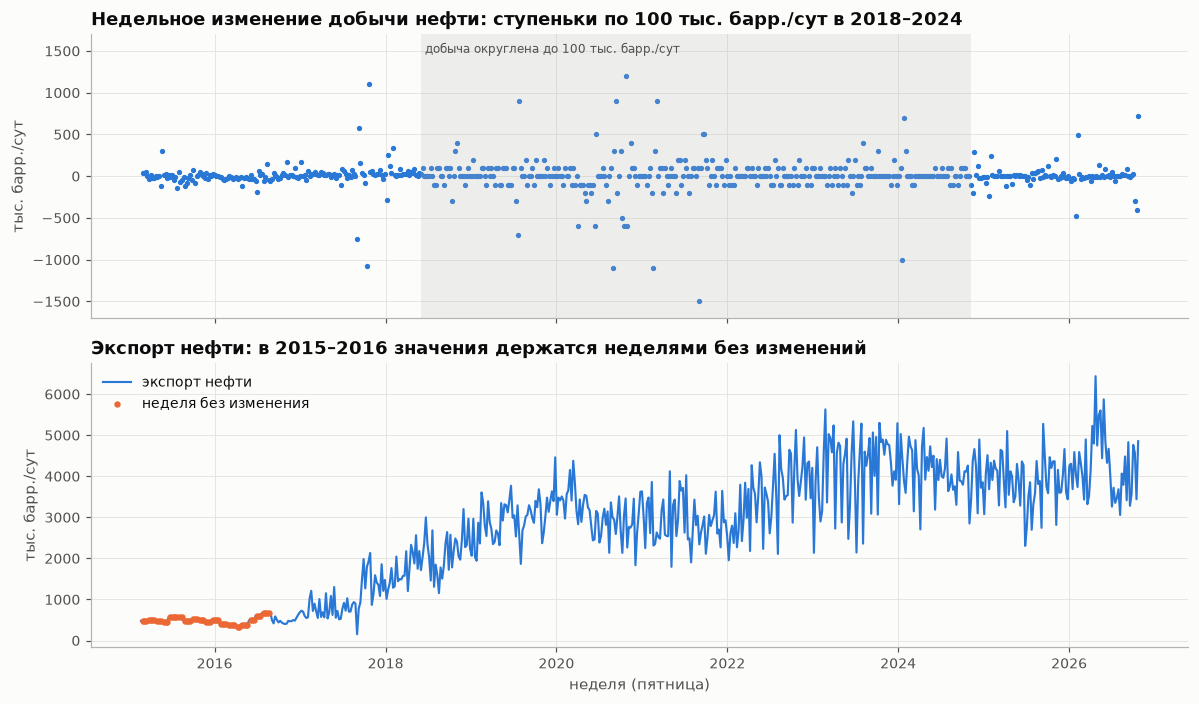

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax = axes[0]
d_prod = df["crude_production"].diff()
ax.scatter(df["period"], d_prod, s=6, color=u.SERIES[0])
r = prod_regimes[prod_regimes["кратно_100"]].iloc[0]
ax.axvspan(r["начало"], r["конец"], color=u.NEUTRAL, alpha=0.2, lw=0)
ax.text(r["начало"], 0.97, " добыча округлена до 100 тыс. барр./сут", transform=ax.get_xaxis_transform(),
        va="top", fontsize=8, color=u.INK_MUTED)
ax.set_ylim(-1700, 1700)
ax.set_title("Недельное изменение добычи нефти: ступеньки по 100 тыс. барр./сут в 2018–2024")
ax.set_ylabel("тыс. барр./сут")

ax = axes[1]
ax.plot(df["period"], df["crude_exports"], color=u.SERIES[0], label="экспорт нефти")
mask = df["crude_exports"].diff() == 0
ax.scatter(df.loc[mask, "period"], df.loc[mask, "crude_exports"], s=10, color=u.SERIES[1],
           label="неделя без изменения", zorder=3)
ax.set_title("Экспорт нефти: в 2015–2016 значения держатся неделями без изменений")
ax.set_ylabel("тыс. барр./сут")
ax.set_xlabel("неделя (пятница)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [8]:
# Выбросы недельного изменения коммерческих запасов: |z| > 3
dS = df["crude_stocks_change_mmbbl"]
z = (dS - dS.mean()) / dS.std()
outliers = df.loc[z.abs() > 3, ["period", "crude_stocks_change_mmbbl", "padd3_stocks_change_mmbbl",
                                "approx_crude_balance_mmbbl", "spr_stocks_change_mmbbl",
                                "refinery_utilization"]].assign(z=z[z.abs() > 3])
num_round(outliers, 2)

,period,crude_stocks_change_mmbbl,padd3_stocks_change_mmbbl,approx_crude_balance_mmbbl,spr_stocks_change_mmbbl,refinery_utilization,z
268,2020-04-10,19.25,10.24,13.15,0.00,69.1,3.57
314,2021-02-26,21.56,20.86,28.27,0.00,56.0,4.00
411,2023-01-06,18.96,15.55,12.33,-0.80,84.1,3.52
416,2023-02-10,16.28,14.50,2.51,0.00,86.5,3.02
440,2023-07-28,-17.05,-15.57,-20.52,0.00,92.7,-3.17
598,2026-08-07,17.42,14.68,6.35,-6.12,96.2,3.23


In [9]:
# Выбросы в потоках: |z| > 4 для недельных изменений
flow_z = {}
for c in ["crude_production", "crude_imports", "crude_exports", "refinery_inputs",
          "refinery_utilization", "total_products_supplied"]:
    dc = df[c].diff()
    zc = (dc - dc.mean()) / dc.std()
    for i in df.index[zc.abs() > 4]:
        flow_z.setdefault(c, []).append(f"{df.at[i, 'period'].date()} ({dc[i]:+.0f})")
print("Недели с |z| > 4 по недельному изменению (в скобках - изменение, тыс. барр./сут или п.п.):")
for k, v in flow_z.items():
    print(f"  {k}: " + ", ".join(v))

Недели с |z| > 4 по недельному изменению (в скобках - изменение, тыс. барр./сут или п.п.):
  crude_production: 2017-10-13 (-1074), 2017-10-20 (+1101), 2019-07-26 (+900), 2020-08-28 (-1100), 2020-09-11 (+900), 2020-10-23 (+1200), 2021-02-19 (-1100), 2021-03-05 (+900), 2021-09-03 (-1500), 2024-01-19 (-1000)
  refinery_inputs: 2017-09-01 (-3253), 2021-02-19 (-2589), 2021-02-26 (-2327), 2021-03-05 (+2407), 2021-09-03 (-1636), 2022-12-30 (-2329)
  refinery_utilization: 2017-09-01 (-17), 2021-02-19 (-14), 2021-02-26 (-13), 2021-03-05 (+13), 2021-09-03 (-9), 2022-12-30 (-12)
  total_products_supplied: 2022-12-30 (-4632)


**Вывод.**
- Сумма PADD 1–5 совпадает с национальным рядом с точностью ±2 тыс. барр. (в 286 из 610 недель расхождение 1–2 тыс. барр. —
  округление), сумма ΔPADD отличается от ΔUS не больше чем на 0,004 млн барр.: декомпозиция в разделе 5 точная.
- `crude_production` с 2018-06-01 по 2024-11-08 (337 недель) кратна 100 тыс. барр./сут, 148 из этих недель — без изменения.
  Недельное Δдобычи в этом окне — ступенька округления, а не сигнал; до и после окна значения неокруглённые.
- `crude_exports` в 2015–2016 повторяет прошлое значение 61 неделю (34 в 2015, 27 в 2016): похоже, недельный экспорт тогда
  был оценкой, а не замером, и его Δ в эти годы бессодержательна.
- `spr_stocks` без изменения 165 недель — это норма (резерв неактивен), не дефект.
- Выбросы ΔStocks нефти (|z| > 3) — 6 недель: 2020-04-10 (+19,2, COVID), 2021-02-26 (+21,6, загрузка НПЗ 56 %),
  2023-01-06 (+19,0 — первая неделя test), 2023-02-10 (+16,3 при балансе +2,5), 2023-07-28 (−17,0), 2026-08-07 (+17,4).
  Четыре из шести — в test.
- Выбросы потоков (|z| > 4) погодные: 2017-09-01 (переработка −3253 тыс. барр./сут), 2021-02-19…03-05 (переработка и загрузка),
  2021-09-03 (добыча −1500), 2022-12-30 (переработка −2329, поставки нефтепродуктов −4632). Ураганы подтверждаются HURDAT2
  (ноутбук 06): Harvey был в Мексиканском заливе 24–30.08.2017 (категория 4), Ida — 28–30.08.2021 (категория 4).
  Февраль 2021 и декабрь 2022 по датам совпадают с зимними штормами — это по памяти, в данных таких событий нет.

## 2. Уровни запасов и режимы рынка

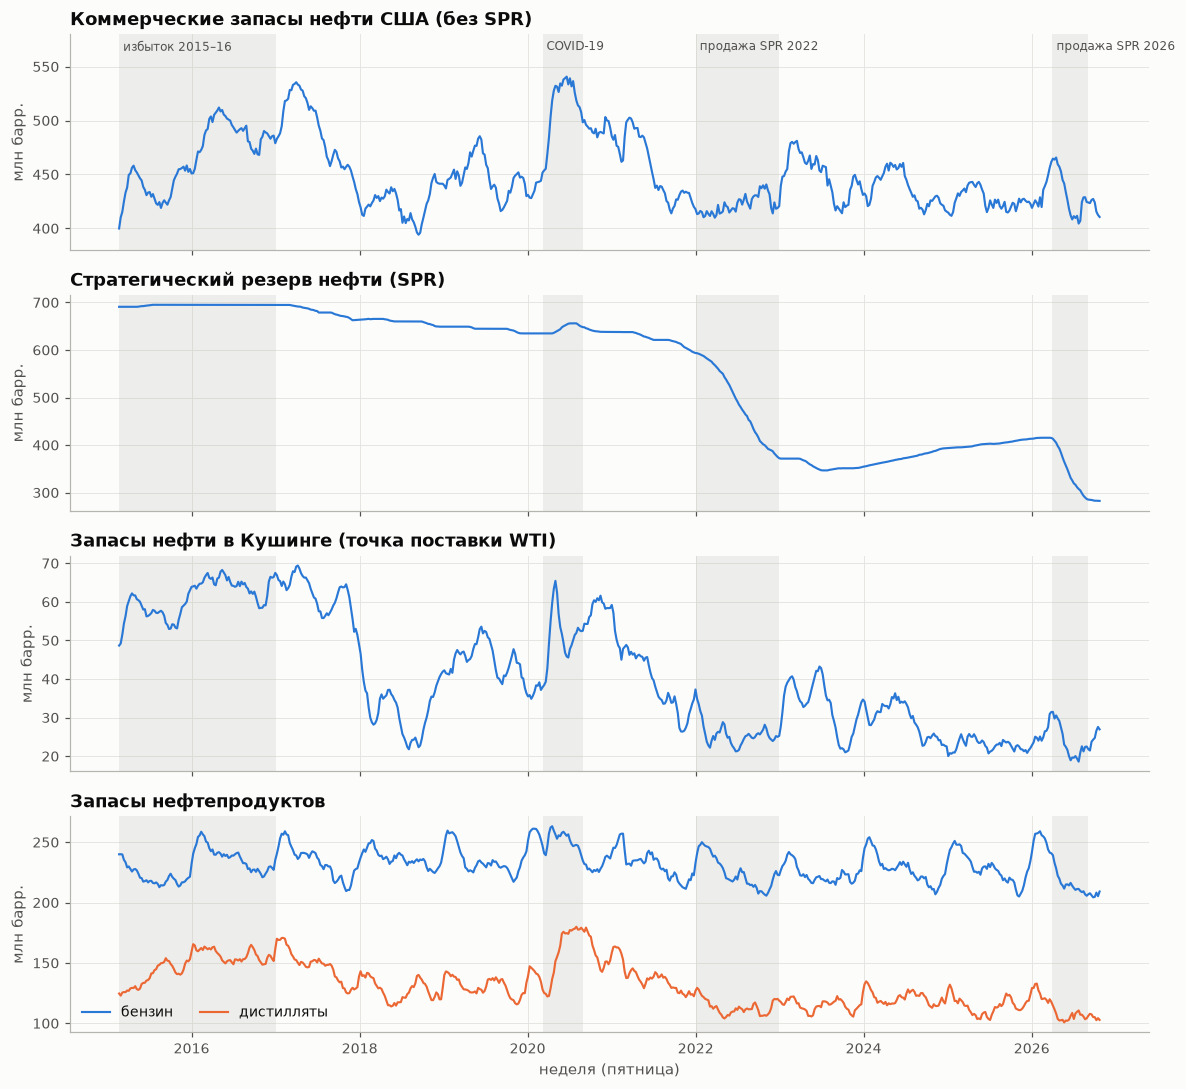

In [10]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
panels = [
    (["crude_stocks_mmbbl"], ["коммерческие запасы без SPR"], "Коммерческие запасы нефти США (без SPR)"),
    (["spr_stocks_mmbbl"], ["SPR"], "Стратегический резерв нефти (SPR)"),
    (["cushing_stocks_mmbbl"], ["Кушинг"], "Запасы нефти в Кушинге (точка поставки WTI)"),
    (["gasoline_stocks_mmbbl", "distillate_stocks_mmbbl"], ["бензин", "дистилляты"],
     "Запасы нефтепродуктов"),
]
for i, (ax, (cols, labels, title)) in enumerate(zip(axes, panels)):
    shade(ax, labels=(i == 0))
    for j, (c, lab) in enumerate(zip(cols, labels)):
        ax.plot(df["period"], df[c], color=u.SERIES[j], label=lab)
    ax.set_title(title)
    ax.set_ylabel("млн барр.")
    if len(cols) > 1:
        ax.legend(loc="lower left", ncol=2)
axes[0].set_ylim(380, 580)
axes[-1].set_xlabel("неделя (пятница)")
fig.tight_layout()
plt.show()

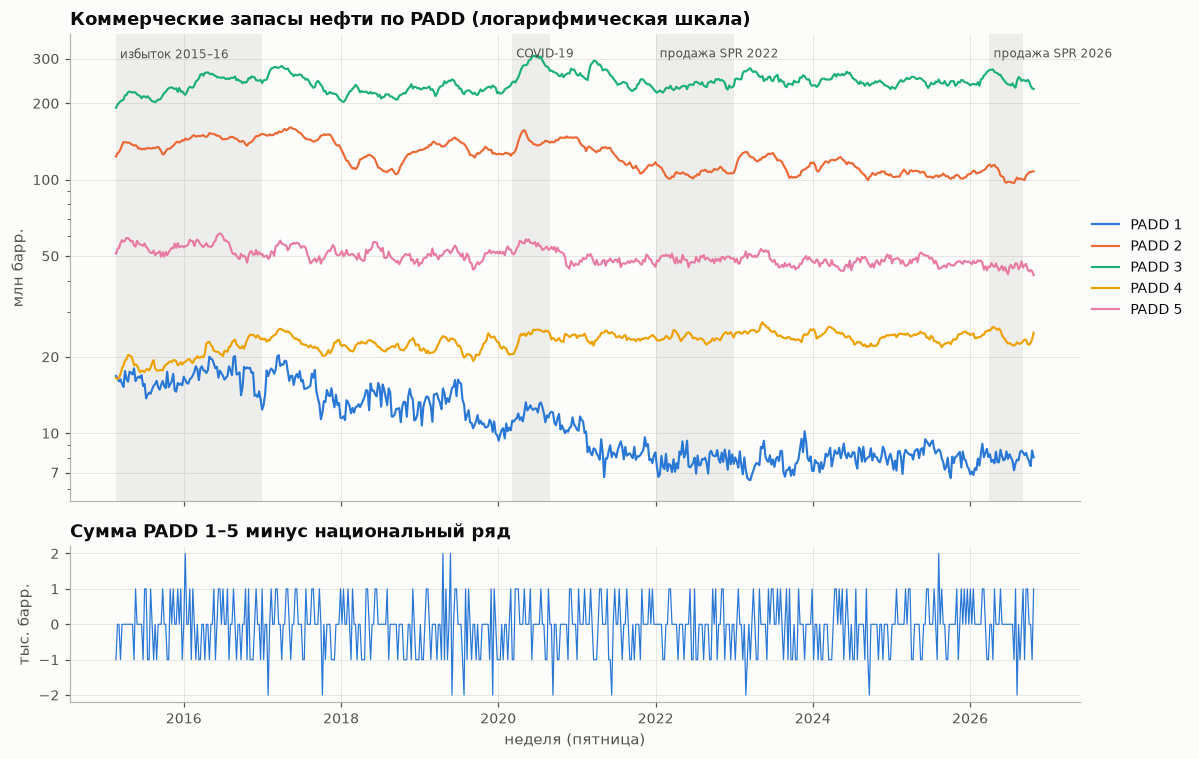

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax = axes[0]
shade(ax, labels=True)
for i in range(1, 6):
    ax.plot(df["period"], df[f"padd{i}_stocks_mmbbl"], color=u.SERIES[i - 1], label=f"PADD {i}")
ax.set_yscale("log")
ax.set_yticks([7, 10, 20, 50, 100, 200, 300])
ax.set_yticklabels(["7", "10", "20", "50", "100", "200", "300"])
ax.set_title("Коммерческие запасы нефти по PADD (логарифмическая шкала)")
ax.set_ylabel("млн барр.")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
ax = axes[1]
ax.plot(df["period"], padd_gap, color=u.SERIES[0], lw=0.8)
ax.set_title("Сумма PADD 1–5 минус национальный ряд")
ax.set_ylabel("тыс. барр.")
ax.set_xlabel("неделя (пятница)")
fig.tight_layout()
plt.show()

In [12]:
level_cols = {
    "crude_stocks_mmbbl": "коммерческие без SPR", "cushing_stocks_mmbbl": "Кушинг",
    "padd1_stocks_mmbbl": "PADD 1", "padd2_stocks_mmbbl": "PADD 2", "padd3_stocks_mmbbl": "PADD 3",
    "padd4_stocks_mmbbl": "PADD 4", "padd5_stocks_mmbbl": "PADD 5", "spr_stocks_mmbbl": "SPR",
    "gasoline_stocks_mmbbl": "бензин", "distillate_stocks_mmbbl": "дистилляты",
}
level_table = pd.DataFrame({
    "мин, млн барр.": idx[list(level_cols)].min(),
    "дата мин": idx[list(level_cols)].idxmin().dt.date,
    "макс, млн барр.": idx[list(level_cols)].max(),
    "дата макс": idx[list(level_cols)].idxmax().dt.date,
    "последнее": idx[list(level_cols)].iloc[-1],
    "среднее 2015–2019": idx.loc[:"2019-12-31", list(level_cols)].mean(),
}).rename(index=level_cols)
num_round(level_table, 1)

,"мин, млн барр.",дата мин,"макс, млн барр.",дата макс,последнее,среднее 2015–2019
коммерческие без SPR,394.1,2018-09-14,540.7,2020-06-19,410.6,457.6
Кушинг,18.6,2026-07-24,69.4,2017-04-07,27.0,52.0
PADD 1,6.5,2023-03-17,20.3,2017-03-17,8.0,14.9
PADD 2,96.9,2026-07-24,161.0,2017-05-12,107.9,136.5
PADD 3,192.1,2015-02-20,309.0,2020-07-03,227.8,232.5
PADD 4,16.4,2015-02-27,27.4,2023-05-12,24.9,21.5
PADD 5,42.0,2026-10-23,61.3,2016-06-17,42.0,52.2
SPR,282.6,2026-10-23,695.1,2015-07-17,282.6,674.6
бензин,204.4,2026-09-25,263.2,2020-04-17,209.2,233.1
дистилляты,100.8,2026-05-22,180.0,2020-07-31,102.8,140.3


In [13]:
# Пик избытка 2015-2017 и объём эпизодов продажи из SPR (суммы недельных ΔSPR в окнах REGIMES)
peak17 = idx.loc[:"2017-12-31", "crude_stocks_mmbbl"]
print(f"Коммерческие запасы: старт {idx['crude_stocks_mmbbl'].iloc[0]:.1f} (2015-02-20), "
      f"пик 2015-2017 {peak17.max():.1f} ({peak17.idxmax().date()})")
for start, end, name in REGIMES:
    if "SPR" in name:
        w = idx.loc[start:end, "spr_stocks_change_mmbbl"]
        print(f"{name}: ΣΔSPR = {w.sum():.1f} млн барр. за {len(w)} нед. (в среднем {w.mean():.2f} в неделю)")

Коммерческие запасы: старт 399.9 (2015-02-20), пик 2015-2017 535.5 (2017-03-31)
продажа SPR 2022: ΣΔSPR = -221.3 млн барр. за 52 нед. (в среднем -4.26 в неделю)
продажа SPR 2026: ΣΔSPR = -129.7 млн барр. за 23 нед. (в среднем -5.64 в неделю)


**Вывод.**
- Коммерческие запасы: 399,9 млн барр. в начале выборки → пик избытка 535,5 (2017-03-31) → минимум 394,1 (2018-09-14) →
  абсолютный максимум 540,7 (2020-06-19, COVID). Последнее значение 410,6 — ниже среднего 2015–2019 (457,6).
- Кушинг структурно опустел: 69,4 (2017-04-07) → минимум выборки 18,6 (2026-07-24), сейчас 27,0 при среднем 2015–2019 52,0.
  PADD 1 сжался с 20,3 до 6,5–8,0 млн барр., PADD 2 — до минимума 96,9 (2026-07-24).
- SPR: 695,1 (2015-07-17) → 282,6 (2026-10-23, минимум выборки). Два эпизода продаж: 2022 г. — −221,3 млн барр.
  за 52 недели (−4,26 в неделю), апрель–сентябрь 2026 — −129,7 за 23 недели (−5,64 в неделю).
- Запасы бензина (204,4, 2026-09-25) и дистиллятов (100,8, 2026-05-22) в 2026 г. на минимумах выборки; максимумы обоих — в 2020 г.
- Тождество Σ PADD = США выполняется все 610 недель (±2 тыс. барр.).

## 3. Сезонность

Профили по неделе года (ISO-неделя пятницы отчёта, 53-я объединена с 52-й). Доля дисперсии, объяснённая
средними по неделе года: in-sample R² на всей выборке (52 параметра — даже на шуме даст ~52/609 ≈ 8,5 %),
скорректированный R² и out-of-sample R² (средние по train применены к test, база — среднее train).

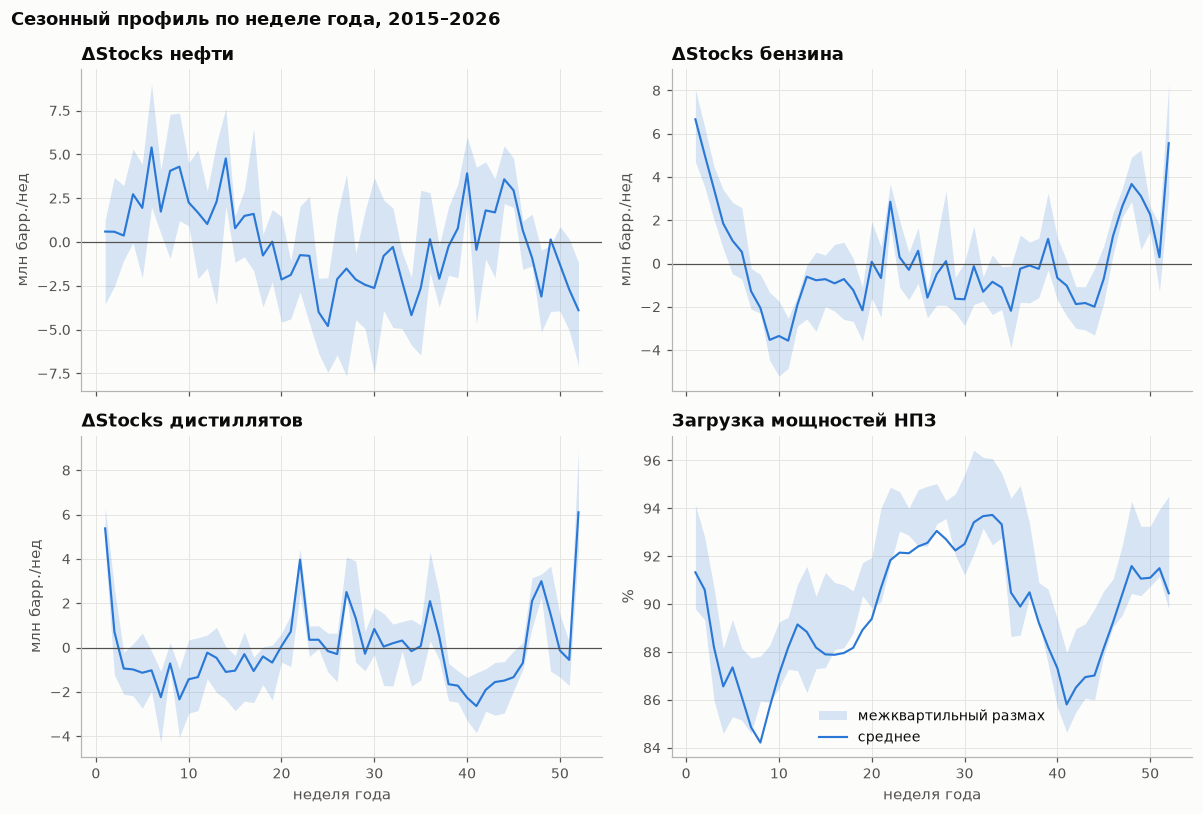

In [14]:
woy_all = week_of_year(df["period"]).to_numpy()
is_train_row = (df["period"] <= TRAIN_END).to_numpy()
season_vars = {
    "crude_stocks_change_mmbbl": ("ΔStocks нефти", "млн барр./нед"),
    "gasoline_stocks_change_mmbbl": ("ΔStocks бензина", "млн барр./нед"),
    "distillate_stocks_change_mmbbl": ("ΔStocks дистиллятов", "млн барр./нед"),
    "refinery_utilization": ("Загрузка мощностей НПЗ", "%"),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, (col, (name, unit)) in zip(axes.ravel(), season_vars.items()):
    g = df[col].groupby(woy_all)
    prof = pd.DataFrame({"mean": g.mean(), "q25": g.quantile(0.25), "q75": g.quantile(0.75)})
    ax.fill_between(prof.index, prof["q25"], prof["q75"], color=u.SERIES[0], alpha=0.18, lw=0,
                    label="межквартильный размах")
    ax.plot(prof.index, prof["mean"], color=u.SERIES[0], label="среднее")
    if col != "refinery_utilization":
        ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_title(name)
    ax.set_ylabel(unit)
for ax in axes[1]:
    ax.set_xlabel("неделя года")
axes[1, 1].legend(loc="lower center")
fig.suptitle("Сезонный профиль по неделе года, 2015–2026", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [15]:
def seasonal_r2(col):
    y_all = df[col]
    ok = y_all.notna().to_numpy()
    y_ok, w_ok, tr_ok = y_all[ok].to_numpy(), woy_all[ok], is_train_row[ok]
    # in-sample, вся выборка
    means = pd.Series(y_ok).groupby(w_ok).transform("mean").to_numpy()
    r2 = 1 - ((y_ok - means) ** 2).sum() / ((y_ok - y_ok.mean()) ** 2).sum()
    n, k = len(y_ok), len(np.unique(w_ok))
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - k)
    # out-of-sample: средние train -> test, база - среднее train
    tr_means = pd.Series(y_ok[tr_ok]).groupby(w_ok[tr_ok]).mean()
    pred = tr_means.reindex(w_ok[~tr_ok]).to_numpy()
    y_te = y_ok[~tr_ok]
    r2_oos = 1 - ((y_te - pred) ** 2).sum() / ((y_te - y_ok[tr_ok].mean()) ** 2).sum()
    return {"R² in-sample": r2, "R² скорр.": r2_adj, "R² OOS (train→test)": r2_oos, "n": n}


season_table = pd.DataFrame({name: seasonal_r2(col) for col, (name, _) in season_vars.items()}).T
season_table["n"] = season_table["n"].astype(int)
num_round(season_table, 3)

,R² in-sample,R² скорр.,R² OOS (train→test),n
ΔStocks нефти,0.205,0.132,0.055,609
ΔStocks бензина,0.469,0.421,0.419,609
ΔStocks дистиллятов,0.412,0.359,0.287,609
Загрузка мощностей НПЗ,0.197,0.124,0.329,610


In [16]:
# Квартальные средние ΔStocks нефти (направление сезонного цикла), млн барр./нед
q_mean = (df.assign(квартал=df["period"].dt.quarter)
          .groupby("квартал")[["crude_stocks_change_mmbbl", "gasoline_stocks_change_mmbbl",
                               "distillate_stocks_change_mmbbl", "refinery_utilization"]].mean())
num_round(q_mean, 2)

,crude_stocks_change_mmbbl,gasoline_stocks_change_mmbbl,distillate_stocks_change_mmbbl,refinery_utilization
квартал,,,,
1,2.21,0.16,-0.49,87.49
2,-0.69,-0.33,0.07,89.94
3,-1.56,-0.73,0.30,91.81
4,0.27,0.76,-0.05,89.00


**Вывод.**
- У нефти сезонность слабая: в среднем накопление в I квартале (+2,21 млн барр./нед) и отбор во II–III (−0,69 и −1,56).
  Средние по неделе года объясняют 20,5 % дисперсии in-sample, но скорректированный R² лишь 13,2 %, а out-of-sample — 5,5 %.
- У нефтепродуктов сезонность сильная и устойчивая: бензин R² 0,469 / скорр. 0,421 / OOS 0,419 (накопление в декабре–январе,
  отбор в феврале–марте), дистилляты 0,412 / 0,359 / 0,287.
- Загрузка НПЗ: провалы в феврале и октябре (сезон ремонтов), пик летом (квартальные средние 87,5 % в I кв. и 91,8 % в III кв.);
  OOS R² 0,329 выше in-sample 0,197, потому что провалы 2020 и 2021 гг. попали в train.
- Сезонное среднее по неделе года — разумный признак или бейзлайн, но для ΔStocks нефти его нужно сглаживать (раздел 8).

## 4. Изменение коммерческих запасов нефти: распределение, автокорреляция, стационарность

In [17]:
dSv = dS.dropna()
moments = pd.Series({
    "n": len(dSv), "среднее": dSv.mean(), "медиана": dSv.median(), "ст. откл.": dSv.std(),
    "асимметрия": stats.skew(dSv), "эксцесс (избыточный)": stats.kurtosis(dSv),
    "p-value Жарка–Бера": stats.jarque_bera(dSv).pvalue,
    "квантиль 1 %": dSv.quantile(0.01), "квантиль 5 %": dSv.quantile(0.05),
    "квантиль 95 %": dSv.quantile(0.95), "квантиль 99 %": dSv.quantile(0.99),
    "доля |z| > 3, %": 100 * (z.abs() > 3).mean(),
    "доля |z| > 3 при нормальности, %": 100 * 2 * stats.norm.sf(3),
    "доля недель с ростом запасов, %": 100 * (dSv > 0).mean(),
    "ст. откл. train": dSv[df.loc[dSv.index, "period"] <= TRAIN_END].std(),
    "ст. откл. test": dSv[df.loc[dSv.index, "period"] > TRAIN_END].std(),
}, name="ΔStocks нефти, млн барр.")
moments.round(3).to_frame()

,"ΔStocks нефти, млн барр."
n,609.000
среднее,0.018
медиана,-0.426
ст. откл.,5.383
асимметрия,0.422
эксцесс (избыточный),0.906
p-value Жарка–Бера,0.000
квантиль 1 %,-12.102
квантиль 5 %,-7.984
квантиль 95 %,8.686


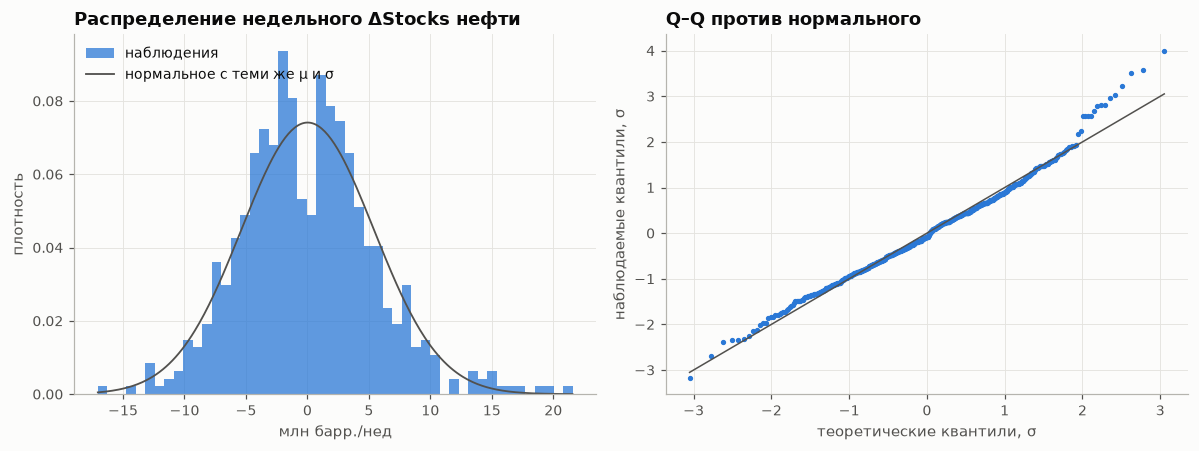

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.hist(dSv, bins=50, density=True, color=u.SERIES[0], alpha=0.75, label="наблюдения")
xs = np.linspace(dSv.min(), dSv.max(), 300)
ax.plot(xs, stats.norm.pdf(xs, dSv.mean(), dSv.std()), color=u.INK_MUTED, lw=1.2,
        label="нормальное с теми же μ и σ")
ax.set_title("Распределение недельного ΔStocks нефти")
ax.set_xlabel("млн барр./нед")
ax.set_ylabel("плотность")
ax.legend(loc="upper left")
ax = axes[1]
(osm, osr), (slope, intercept, _) = stats.probplot((dSv - dSv.mean()) / dSv.std(), dist="norm")
ax.scatter(osm, osr, s=6, color=u.SERIES[0])
ax.plot(osm, osm, color=u.INK_MUTED, lw=1)
ax.set_title("Q–Q против нормального")
ax.set_xlabel("теоретические квантили, σ")
ax.set_ylabel("наблюдаемые квантили, σ")
fig.tight_layout()
plt.show()

In [19]:
top_abs = df.loc[dS.abs().nlargest(10).index, ["period", "crude_stocks_change_mmbbl",
                                               "approx_crude_balance_mmbbl", "spr_stocks_change_mmbbl",
                                               "refinery_utilization", "crude_imports", "crude_exports"]]
num_round(top_abs.sort_values("period"), 2)

,period,crude_stocks_change_mmbbl,approx_crude_balance_mmbbl,spr_stocks_change_mmbbl,refinery_utilization,crude_imports,crude_exports
267,2020-04-03,15.18,12.65,0.00,75.6,5874,2833
268,2020-04-10,19.25,13.15,0.00,69.1,5680,3436
269,2020-04-17,15.02,12.54,0.00,67.6,4937,2890
302,2020-12-04,15.19,9.16,-0.11,79.9,6479,1834
314,2021-02-26,21.56,28.27,0.00,56.0,6292,2351
411,2023-01-06,18.96,12.33,-0.80,84.1,6350,2137
416,2023-02-10,16.28,2.51,0.00,86.5,6232,3146
440,2023-07-28,-17.05,-20.52,0.00,92.7,6668,5283
574,2026-02-20,15.99,2.71,0.00,88.6,6659,4313
598,2026-08-07,17.42,6.35,-6.12,96.2,7339,3058


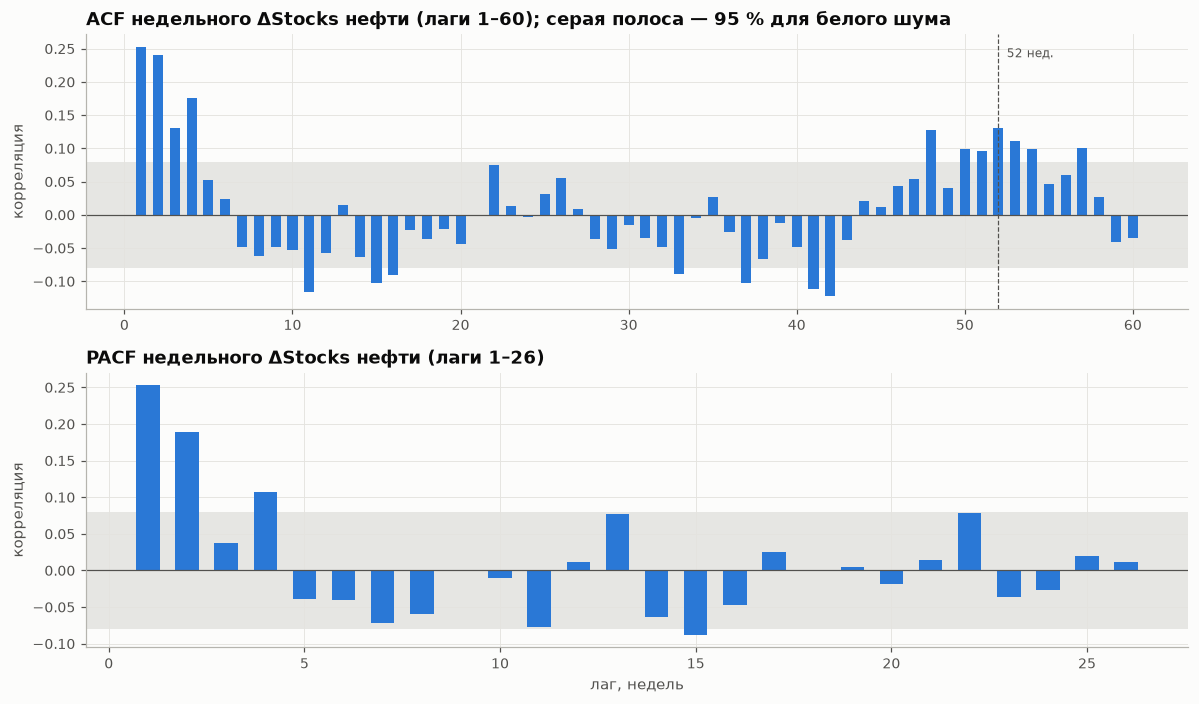

ACF лаги 1-6: [0.253 0.241 0.131 0.176 0.052 0.023] | лаг 52: 0.131
PACF лаги 1-6: [ 0.253  0.189  0.038  0.108 -0.039 -0.041]
95%-полоса: ± 0.079


,lb_stat,lb_pvalue
4,104.3869,0.0
8,110.1903,0.0
26,147.0945,0.0
52,227.9321,0.0


In [20]:
n_obs = len(dSv)
acf_vals = acf(dSv, nlags=60, fft=True)
pacf_vals = pacf(dSv, nlags=26, method="ywm")
band = 1.96 / np.sqrt(n_obs)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, vals, title in [(axes[0], acf_vals, "ACF недельного ΔStocks нефти (лаги 1–60); серая полоса — 95 % для белого шума"),
                        (axes[1], pacf_vals, "PACF недельного ΔStocks нефти (лаги 1–26)")]:
    lags = np.arange(1, len(vals))
    ax.axhspan(-band, band, color=u.NEUTRAL, alpha=0.3, lw=0, zorder=0,)
    ax.bar(lags, vals[1:], width=0.6, color=u.SERIES[0], zorder=2)
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_title(title)
    ax.set_ylabel("корреляция")
axes[0].axvline(52, color=u.INK_MUTED, lw=0.8, ls="--")
axes[0].text(52.5, 0.95, "52 нед.", transform=axes[0].get_xaxis_transform(), va="top", fontsize=8,
             color=u.INK_MUTED)
axes[1].set_xlabel("лаг, недель")
fig.tight_layout()
plt.show()

print("ACF лаги 1-6:", np.round(acf_vals[1:7], 3), "| лаг 52:", round(acf_vals[52], 3))
print("PACF лаги 1-6:", np.round(pacf_vals[1:7], 3))
print("95%-полоса: ±", round(band, 3))
acorr_ljungbox(dSv, lags=[4, 8, 26, 52]).round(4)

In [21]:
# Автокорреляция после вычитания сезонных средних по неделе года (средние по всей выборке)
dS_deseason = (dS - dS.groupby(woy_all).transform("mean")).dropna()
acf_ds = acf(dS_deseason, nlags=8, fft=True)
print("ACF ΔStocks без сезонных средних, лаги 1-8:", np.round(acf_ds[1:], 3))

ACF ΔStocks без сезонных средних, лаги 1-8: [ 0.152  0.167  0.053  0.115 -0.009  0.021 -0.049 -0.054]


In [22]:
def unit_root_tests(x):
    x = pd.Series(x).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # KPSS предупреждает, когда p-value за пределами таблицы
        adf_p = adfuller(x, autolag="AIC")[1]
        kpss_p = kpss(x, regression="c", nlags="auto")[1]
    return {"ADF p-value (H0: единичный корень)": adf_p, "KPSS p-value (H0: стационарность)": kpss_p}


ur_series = {
    "уровень коммерческих запасов": df["crude_stocks_mmbbl"],
    "ΔStocks нефти": df["crude_stocks_change_mmbbl"],
    "уровень Кушинга": df["cushing_stocks_mmbbl"],
    "ΔStocks Кушинга": df["cushing_stocks_change_mmbbl"],
    "уровень SPR": df["spr_stocks_mmbbl"],
    "приближённый баланс": df["approx_crude_balance_mmbbl"],
    "невязка adjustment (разд. 6)": df["crude_stocks_change_mmbbl"] + df["spr_stocks_change_mmbbl"]
                                     - df["approx_crude_balance_mmbbl"],
}
ur_table = pd.DataFrame({k: unit_root_tests(v) for k, v in ur_series.items()}).T
print("KPSS p-value в statsmodels ограничен диапазоном [0.01, 0.10]")
ur_table.round(3)

KPSS p-value в statsmodels ограничен диапазоном [0.01, 0.10]


,ADF p-value (H0: единичный корень),KPSS p-value (H0: стационарность)
уровень коммерческих запасов,0.006,0.01
ΔStocks нефти,0.000,0.10
уровень Кушинга,0.393,0.01
ΔStocks Кушинга,0.000,0.10
уровень SPR,0.938,0.01
приближённый баланс,0.001,0.01
невязка adjustment (разд. 6),0.024,0.01


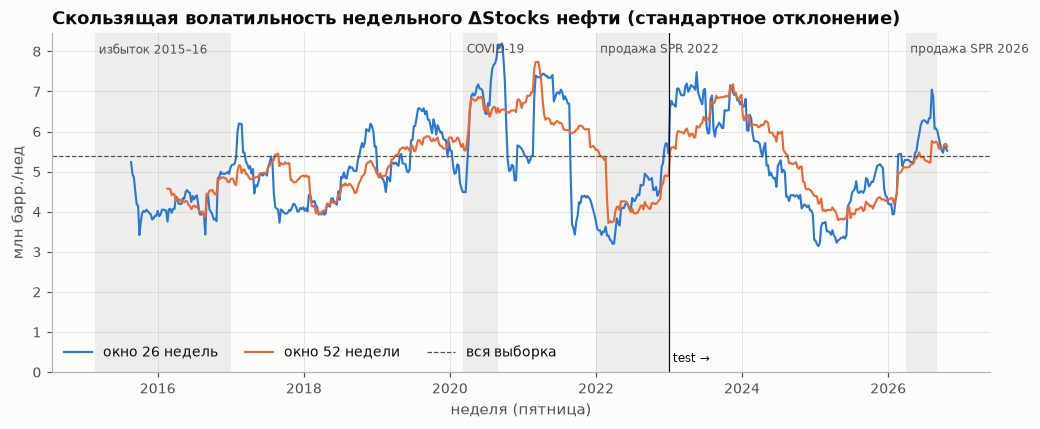

period,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"ст. откл., млн барр.",4.65,4.81,4.9,4.99,5.85,6.59,5.56,4.88,6.91,4.39,4.27,6.0
недель,44.00,53.00,52.0,52.00,52.00,52.00,53.00,52.00,52.00,52.00,52.00,43.0


In [23]:
roll26 = idx["crude_stocks_change_mmbbl"].rolling(26).std()
roll52 = idx["crude_stocks_change_mmbbl"].rolling(52).std()
fig, ax = plt.subplots(figsize=(11, 4))
shade(ax, labels=True)
ax.plot(roll26.index, roll26, color=u.SERIES[0], label="окно 26 недель")
ax.plot(roll52.index, roll52, color=u.SERIES[1], label="окно 52 недели")
ax.axhline(dSv.std(), color=u.INK_MUTED, lw=0.8, ls="--", label="вся выборка")
ax.axvline(TRAIN_END, color=u.INK, lw=0.8)
ax.text(TRAIN_END, 0.03, " test →", transform=ax.get_xaxis_transform(), fontsize=8, color=u.INK)
ax.set_title("Скользящая волатильность недельного ΔStocks нефти (стандартное отклонение)")
ax.set_ylabel("млн барр./нед")
ax.set_xlabel("неделя (пятница)")
ax.set_ylim(0, None)
ax.legend(loc="lower left", ncol=3)
plt.show()

std_year = idx.groupby(idx.index.year)["crude_stocks_change_mmbbl"].agg(["std", "count"])
std_year.columns = ["ст. откл., млн барр.", "недель"]
std_year.round(2).T

**Вывод.**
- ΔStocks нефти: σ = 5,38 млн барр./нед, среднее 0,02, медиана −0,43; рост запасов в 48,6 % недель. Асимметрия +0,42,
  избыточный эксцесс 0,91, Жарка–Бера p < 0,001; квантили 1 %/99 % — −12,1/+15,2. Правый хвост тяжелее: крупные приросты
  (шоки погоды и COVID) реже отборов, но больше по размеру. |z| > 3 у 0,98 % недель против 0,27 % при нормальности.
- Память короткая, но есть: ACF 0,253 / 0,241 / 0,131 / 0,176 на лагах 1–4, на лаге 52 — 0,131; PACF значима на лагах 1, 2 и 4
  (0,253, 0,189, 0,108); Ljung–Box p < 0,001. После вычитания сезонных средних ACF лагов 1–2 падает до 0,152/0,167:
  часть инерции даёт сезонность.
- Стационарность: ΔStocks стационарен (ADF p < 0,001, KPSS p ≥ 0,10). Уровень коммерческих запасов противоречив
  (ADF p = 0,006, KPSS p ≤ 0,01): он возвращается к среднему, но само среднее сдвигается. У Кушинга (ADF p = 0,39)
  и SPR (p = 0,94) единичный корень не отвергается. Баланс и adjustment отвергаются обоими тестами: стационарны вокруг дрейфующего среднего.
- Волатильность меняется по режимам: σ по годам от 4,27 (2025) до 6,91 (2023), в 2020 г. — 6,59. В целом train и test близки
  (5,36 и 5,45), но внутри test неоднородно: 2023 — 6,91, 2024–2025 — 4,39 и 4,27, 2026 — 6,00.

## 5. Декомпозиция национального ΔStocks по PADD и Кушингу

Раз ΔUS = Σ ΔPADD_i (раздел 1), дисперсия раскладывается точно: доля региона = Cov(ΔPADD_i, ΔUS) / Var(ΔUS),
доли суммируются в 1. Кушинг входит в PADD 2, поэтому PADD 2 разбит на «Кушинг» и «PADD 2 без Кушинга».

In [24]:
reg = pd.DataFrame({
    "PADD 1": df["padd1_stocks_change_mmbbl"],
    "PADD 2 без Кушинга": df["padd2_stocks_change_mmbbl"] - df["cushing_stocks_change_mmbbl"],
    "Кушинг": df["cushing_stocks_change_mmbbl"],
    "PADD 3": df["padd3_stocks_change_mmbbl"],
    "PADD 4": df["padd4_stocks_change_mmbbl"],
    "PADD 5": df["padd5_stocks_change_mmbbl"],
})
us = df["crude_stocks_change_mmbbl"]


def var_shares(mask):
    r, t = reg[mask], us[mask]
    return r.apply(lambda s: s.cov(t)) / t.var()


train_mask = (df["period"] <= TRAIN_END) & us.notna()
test_mask = (df["period"] > TRAIN_END) & us.notna()
decomp = pd.DataFrame({
    "ст. откл., млн барр.": reg.std(),
    "corr с ΔUS": reg.corrwith(us),
    "доля дисперсии ΔUS": var_shares(us.notna()),
    "доля, train": var_shares(train_mask),
    "доля, test": var_shares(test_mask),
})
decomp.loc["сумма"] = [np.nan, np.nan, decomp["доля дисперсии ΔUS"].sum(),
                       decomp["доля, train"].sum(), decomp["доля, test"].sum()]
decomp.round(3)

,"ст. откл., млн барр.",corr с ΔUS,доля дисперсии ΔUS,"доля, train","доля, test"
PADD 1,0.905,0.212,0.036,0.046,0.014
PADD 2 без Кушинга,1.135,0.221,0.047,0.052,0.035
Кушинг,1.410,0.315,0.082,0.083,0.082
PADD 3,4.554,0.867,0.734,0.702,0.797
PADD 4,0.451,0.304,0.025,0.024,0.028
PADD 5,1.430,0.286,0.076,0.093,0.043
сумма,NaN,NaN,1.000,1.000,1.000


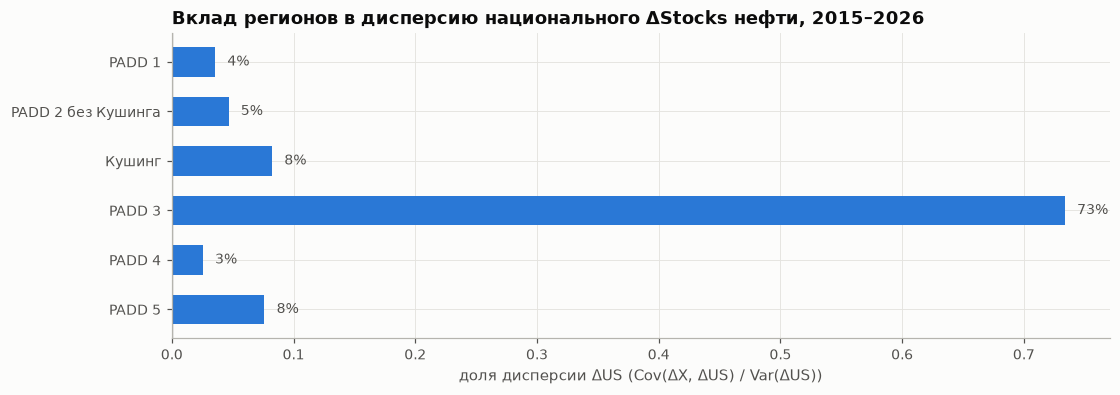

In [25]:
fig, ax = plt.subplots(figsize=(11, 3.6))
shares = decomp["доля дисперсии ΔUS"].drop("сумма")
ax.barh(shares.index[::-1], shares.values[::-1], color=u.SERIES[0], height=0.6)
for yv, v in enumerate(shares.values[::-1]):
    ax.text(v + 0.01 if v >= 0 else 0.01, yv, f"{v:.0%}", va="center", fontsize=9, color=u.INK_MUTED)
ax.axvline(0, color=u.INK_MUTED, lw=0.8)
ax.set_title("Вклад регионов в дисперсию национального ΔStocks нефти, 2015–2026")
ax.set_xlabel("доля дисперсии ΔUS (Cov(ΔX, ΔUS) / Var(ΔUS))")
plt.show()

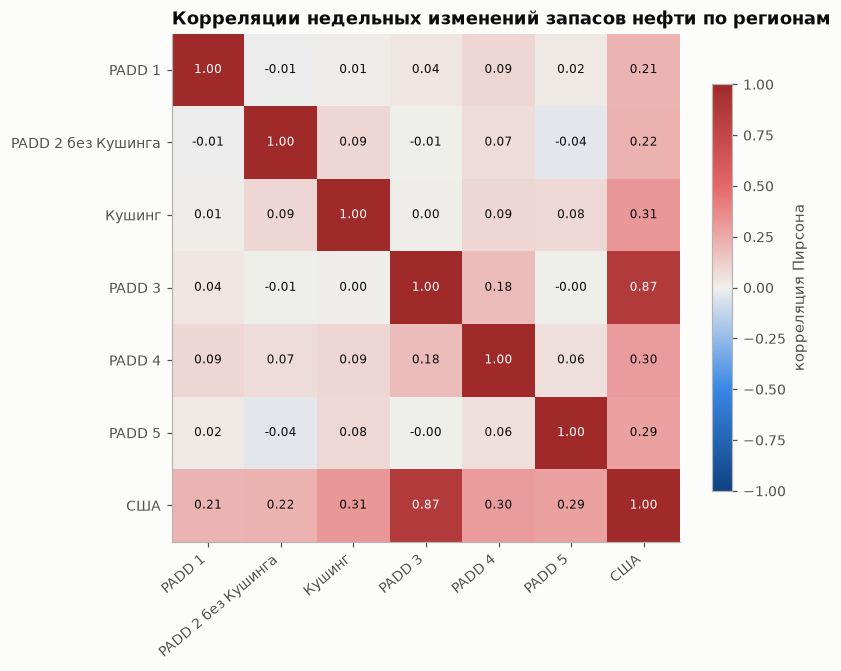

In [26]:
corr_reg = pd.concat([reg, us.rename("США")], axis=1).corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr_reg.values, cmap=u.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_reg)))
ax.set_xticklabels(corr_reg.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr_reg)))
ax.set_yticklabels(corr_reg.index)
for i in range(len(corr_reg)):
    for j in range(len(corr_reg)):
        v = corr_reg.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else u.INK)
ax.grid(False)
ax.set_title("Корреляции недельных изменений запасов нефти по регионам")
fig.colorbar(im, ax=ax, shrink=0.8, label="корреляция Пирсона")
plt.show()

**Вывод.**
- PADD 3 (побережье Мексиканского залива) даёт 73,4 % дисперсии национального ΔStocks (corr 0,867): 70,2 % в train, 79,7 % в test.
  Дальше Кушинг (8,2 %), PADD 5 (7,6 %), PADD 2 без Кушинга (4,7 %), PADD 1 (3,6 %), PADD 4 (2,5 %).
- Регионы между собой почти не коррелируют: максимальная внедиагональная корреляция — 0,18 (PADD 3–PADD 4), остальные |corr| ≤ 0,09.
  Значит, дисперсия национального ряда — почти сумма региональных, а задача прогноза в основном сводится к PADD 3
  (там же сосредоточены импорт и экспорт).
- На Кушинг приходится лишь 8 % дисперсии национального ΔStocks, но для спреда WTI это ключевая точка, и его изменения
  предсказывают национальный ΔStocks на следующей неделе (раздел 7).

## 6. Балансовое тождество: насколько приближённый баланс объясняет ΔStocks

Баланс EIA по нефти (тыс. барр./сут): добыча + чистый импорт + adjustment = переработка на НПЗ + Δ(коммерческие + SPR).
Отсюда, в млн барр./нед: **ΔStocks = approx_balance − ΔSPR + adjustment**. Значит невязка
`ΔStocks − approx_balance` = adjustment − ΔSPR, а сама adjustment = ΔStocks + ΔSPR − approx_balance
(с точностью до статей, которых нет среди наших четырёх потоков). 1 млн барр./нед ≈ 143 тыс. барр./сут.

In [27]:
bal = df["approx_crude_balance_mmbbl"]
dSPR = df["spr_stocks_change_mmbbl"]
resid = dS - bal
adj = dS + dSPR - bal
ok = dS.notna()


def fit_stats(x, y):
    m = x.notna() & y.notna()
    lr = stats.linregress(x[m], y[m])
    e = y[m] - (lr.intercept + lr.slope * x[m])
    return {"R²": lr.rvalue ** 2, "наклон": lr.slope, "свободный член": lr.intercept,
            "RMSE остатка": np.sqrt((e ** 2).mean())}


def identity_stats(pred, y):
    m = pred.notna() & y.notna()
    e = y[m] - pred[m]
    return {"R²": 1 - (e ** 2).sum() / ((y[m] - y[m].mean()) ** 2).sum(), "наклон": 1.0,
            "свободный член": 0.0, "RMSE остатка": np.sqrt((e ** 2).mean())}


bal_table = pd.DataFrame({
    "ΔS = баланс (тождество как есть)": identity_stats(bal, dS),
    "ΔS = баланс − ΔSPR (тождество)": identity_stats(bal - dSPR, dS),
    "ΔS ~ a + b·баланс (OLS)": fit_stats(bal, dS),
    "ΔS ~ a + b·(баланс − ΔSPR) (OLS)": fit_stats(bal - dSPR, dS),
    "ΔS ~ a + b·баланс, только train": fit_stats(bal[is_train_row], dS[is_train_row]),
    "ΔS ~ a + b·баланс, только test": fit_stats(bal[~is_train_row], dS[~is_train_row]),
}).T
bal_table.round(3)

,R²,наклон,свободный член,RMSE остатка
ΔS = баланс (тождество как есть),-0.213,1.000,0.000,5.924
ΔS = баланс − ΔSPR (тождество),0.116,1.000,0.000,5.055
ΔS ~ a + b·баланс (OLS),0.506,0.572,2.041,3.782
ΔS ~ a + b·(баланс − ΔSPR) (OLS),0.567,0.651,1.882,3.539
"ΔS ~ a + b·баланс, только train",0.546,0.606,1.717,3.604
"ΔS ~ a + b·баланс, только test",0.465,0.553,2.799,3.974


In [28]:
# Точная декомпозиция дисперсии: Var(ΔS) = Cov(ΔS, баланс) + Cov(ΔS, −ΔSPR) + Cov(ΔS, adjustment)
v = dS[ok].var()
var_decomp = pd.Series({
    "приближённый баланс": dS[ok].cov(bal[ok]) / v,
    "−ΔSPR": dS[ok].cov(-dSPR[ok]) / v,
    "adjustment": dS[ok].cov(adj[ok]) / v,
}, name="доля Var(ΔStocks)")
var_decomp["сумма"] = var_decomp.sum()
print("Ст. откл.: ΔS", round(dS.std(), 2), "| баланс", round(bal.std(), 2), "| adjustment",
      round(adj.std(), 2), "| ΔSPR", round(dSPR.std(), 2), "млн барр./нед")
print("corr(баланс, adjustment) =", round(bal.corr(adj), 3))
var_decomp.round(3).to_frame()

Ст. откл.: ΔS 5.38 | баланс 6.69 | adjustment 4.16 | ΔSPR 1.87 млн барр./нед
corr(баланс, adjustment) = -0.519


,доля Var(ΔStocks)
приближённый баланс,0.883
−ΔSPR,-0.012
adjustment,0.129
сумма,1.000


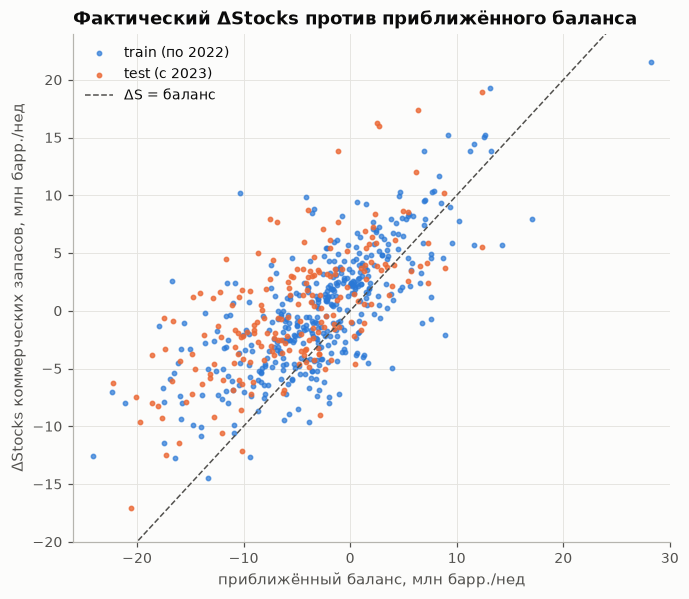

In [29]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(bal[is_train_row], dS[is_train_row], s=8, color=u.SERIES[0], alpha=0.7, label="train (по 2022)")
ax.scatter(bal[~is_train_row], dS[~is_train_row], s=8, color=u.SERIES[1], alpha=0.8, label="test (с 2023)")
lim = [-26, 30]
ax.plot(lim, lim, color=u.INK_MUTED, lw=1, ls="--", label="ΔS = баланс")
ax.set_xlim(lim)
ax.set_ylim(-20, 24)
ax.set_title("Фактический ΔStocks против приближённого баланса")
ax.set_xlabel("приближённый баланс, млн барр./нед")
ax.set_ylabel("ΔStocks коммерческих запасов, млн барр./нед")
ax.legend(loc="upper left")
plt.show()

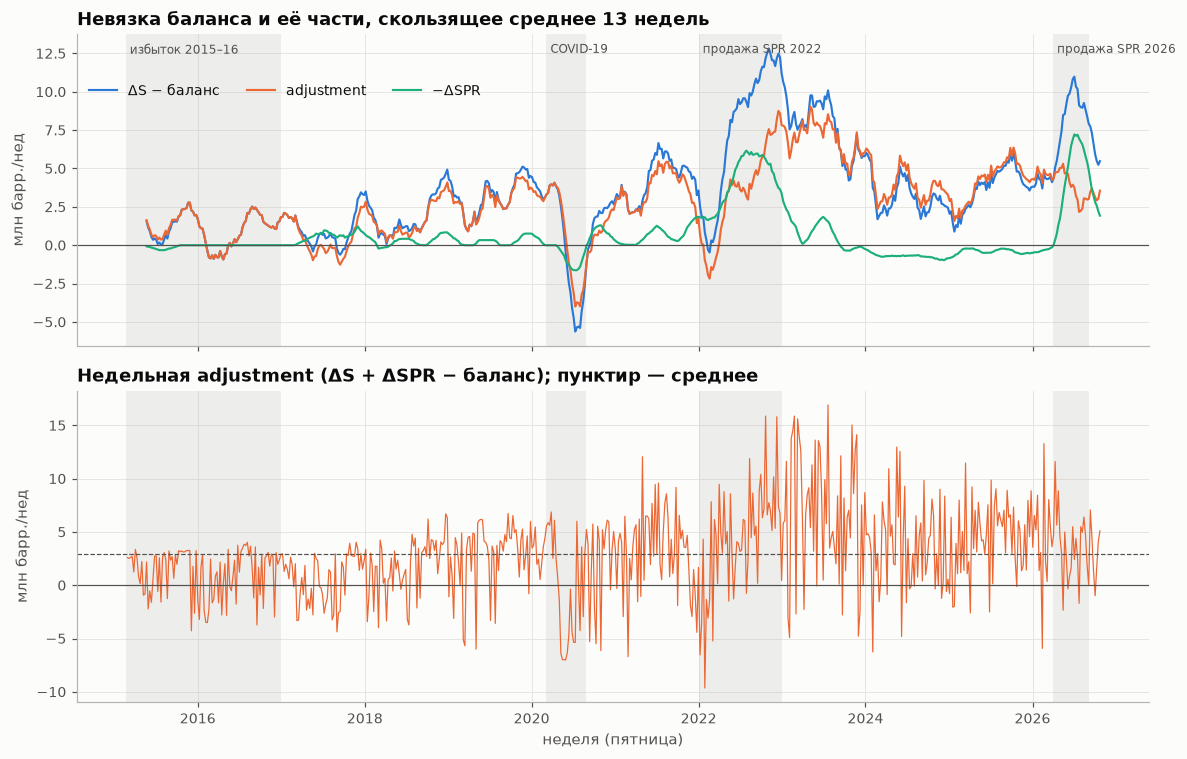

In [30]:
roll = 13
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax = axes[0]
shade(ax, labels=True)
ax.plot(df["period"], resid.rolling(roll).mean(), color=u.SERIES[0], label="ΔS − баланс")
ax.plot(df["period"], adj.rolling(roll).mean(), color=u.SERIES[1], label="adjustment")
ax.plot(df["period"], (-dSPR).rolling(roll).mean(), color=u.SERIES[2], label="−ΔSPR")
ax.axhline(0, color=u.INK_MUTED, lw=0.8)
ax.set_title(f"Невязка баланса и её части, скользящее среднее {roll} недель")
ax.set_ylabel("млн барр./нед")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88), ncol=3)
ax = axes[1]
shade(ax)
ax.plot(df["period"], adj, color=u.SERIES[1], lw=0.8)
ax.axhline(0, color=u.INK_MUTED, lw=0.8)
ax.axhline(adj.mean(), color=u.INK_MUTED, lw=0.8, ls="--")
ax.set_title("Недельная adjustment (ΔS + ΔSPR − баланс); пунктир — среднее")
ax.set_ylabel("млн барр./нед")
ax.set_xlabel("неделя (пятница)")
fig.tight_layout()
plt.show()

In [31]:
by_year = pd.DataFrame({
    "corr(ΔS, баланс)": [dS[g].corr(bal[g]) for g in [df["period"].dt.year == yv for yv in sorted(df["period"].dt.year.unique())]],
}, index=sorted(df["period"].dt.year.unique()))
yr = df["period"].dt.year
by_year["ΔS среднее"] = dS.groupby(yr).mean()
by_year["баланс среднее"] = bal.groupby(yr).mean()
by_year["ΔSPR среднее"] = dSPR.groupby(yr).mean()
by_year["adjustment среднее"] = adj.groupby(yr).mean()
by_year["adjustment, тыс. барр./сут"] = adj.groupby(yr).mean() * 1000 / 7
by_year["adjustment ст. откл."] = adj.groupby(yr).std()
by_year.index.name = "год"
by_year.round(2)

,"corr(ΔS, баланс)",ΔS среднее,баланс среднее,ΔSPR среднее,adjustment среднее,"adjustment, тыс. барр./сут",adjustment ст. откл.
год,,,,,,,
2015,0.91,1.25,-0.05,0.09,1.53,219.19,1.97
2016,0.87,0.45,-0.41,-0.00,0.86,123.39,2.44
2017,0.90,-1.05,-2.19,-0.60,0.54,76.50,2.29
2018,0.83,0.33,-1.77,-0.28,1.81,258.89,2.65
2019,0.83,-0.22,-3.28,-0.27,2.79,398.35,3.20
2020,0.73,1.22,0.24,0.06,1.05,149.64,4.54
2021,0.87,-1.43,-5.51,-0.84,3.24,463.40,3.82
2022,0.57,0.05,-8.48,-4.26,4.28,611.24,5.08
2023,0.66,0.20,-6.92,-0.35,6.78,968.02,6.02


In [32]:
adj_acf = acf(adj.dropna(), nlags=6, fft=True)
adj_dev = (adj - adj.rolling(52, min_periods=26).mean().shift(1)).dropna()
adj_dev_acf = acf(adj_dev, nlags=6, fft=True)
pd.DataFrame({"ACF adjustment": adj_acf[1:], "ACF отклонения от среднего за 52 нед.": adj_dev_acf[1:]},
             index=pd.Index(range(1, 7), name="лаг")).round(3).T

лаг,1,2,3,4,5,6
ACF adjustment,0.226,0.330,0.283,0.324,0.299,0.229
ACF отклонения от среднего за 52 нед.,0.121,0.239,0.184,0.229,0.203,0.123


**Вывод.**
- «Как есть» приближённый баланс смещён: его среднее −3,52 против 0,02 у ΔStocks, средняя невязка +3,55 млн барр./нед.
  Как тождество он объясняет хуже константы (R² −0,21), с поправкой на ΔSPR — R² 0,116. Через OLS: R² 0,506
  (наклон 0,57, свободный член 2,04), с ΔSPR — 0,567. В train R² 0,546, в test 0,465.
- Наклон меньше 1, потому что adjustment отрицательно коррелирует с балансом (−0,52): шум недельных оценок потоков
  (импорт, экспорт) гасится в adjustment. По дисперсии: Cov-доля баланса 88,3 %, adjustment 12,9 %, −ΔSPR −1,2 %.
- Adjustment растёт: 0,5–1,8 млн барр./нед (77–259 тыс. барр./сут) в 2015–2018 → 3,2–6,8 (463–968 тыс. барр./сут)
  в 2021–2026, пик в 2023 г.; разброс тоже вырос (σ 2,0–2,7 → 3,4–6,0). Невязка ΔS − баланс дополнительно подскакивает
  при продажах из SPR (2022: ΔSPR в среднем −4,26 млн барр./нед; 2026: −3,04 в среднем за год).
- У adjustment есть инерция: ACF 0,23–0,33 на лагах 1–6, после вычитания скользящего среднего за 52 недели — 0,12–0,24.
  Но прогнозной силы adjustment[t−1] для ΔStocks почти не несёт, и она нестабильна (corr −0,07; train −0,001, test −0,183).
- Оговорка: наша «adjustment» — это adjustment EIA плюс любые статьи баланса, которых нет среди четырёх потоков
  (по памяти — например, transfers to crude oil supply; по данным это не проверено).

## 7. Потоки и ΔStocks: синхронные корреляции и лаги

Для каждой недели t считаем corr(ΔX_{t−k}, ΔStocks_t), где ΔX — недельное изменение потока. k = 0 — та же неделя
(выходит в том же отчёте, **для прогноза недоступно**), k ≥ 1 — прошлые недели (известны до релиза),
k < 0 — будущие недели (для понимания динамики). Порог значимости ±1,96/√n.

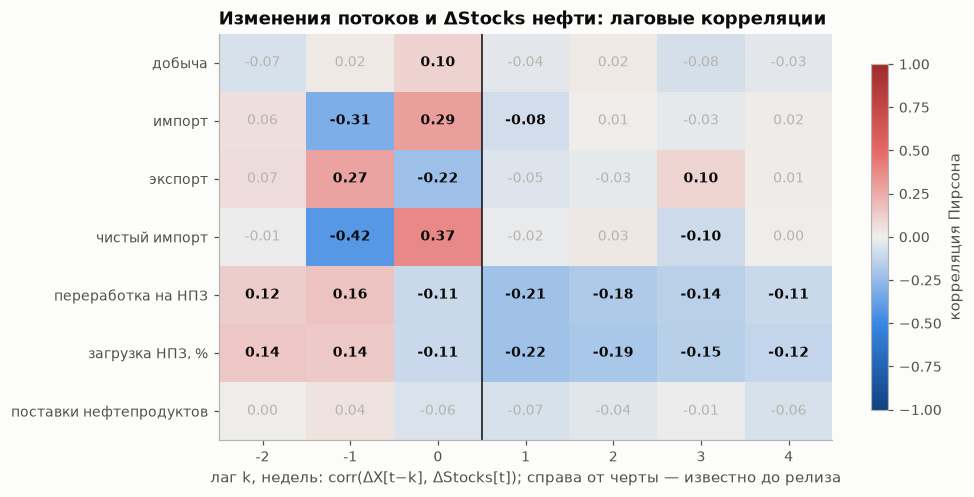

Порог значимости ±0.079; жирным — значимые


In [33]:
flow_names = {
    "crude_production": "добыча",
    "crude_imports": "импорт",
    "crude_exports": "экспорт",
    "net_crude_imports": "чистый импорт",
    "refinery_inputs": "переработка на НПЗ",
    "refinery_utilization": "загрузка НПЗ, %",
    "total_products_supplied": "поставки нефтепродуктов",
}
lag_list = list(range(-2, 5))
ll = pd.DataFrame({k: [dS.corr(df[c].diff().shift(k)) for c in flow_names] for k in lag_list},
                  index=list(flow_names.values()))
sig = 1.96 / np.sqrt(dS.notna().sum())

fig, ax = plt.subplots(figsize=(9, 4.8))
im = ax.imshow(ll.values, cmap=u.DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(lag_list)))
ax.set_xticklabels([f"{k}" for k in lag_list])
ax.set_yticks(range(len(ll)))
ax.set_yticklabels(ll.index)
for i in range(ll.shape[0]):
    for j in range(ll.shape[1]):
        val = ll.values[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9,
                color=u.INK if abs(val) >= sig else u.NEUTRAL,
                fontweight="bold" if abs(val) >= sig else "normal")
ax.axvline(lag_list.index(0) + 0.5, color=u.INK, lw=1)
ax.grid(False)
ax.set_xlabel("лаг k, недель: corr(ΔX[t−k], ΔStocks[t]); справа от черты — известно до релиза")
ax.set_title("Изменения потоков и ΔStocks нефти: лаговые корреляции")
fig.colorbar(im, ax=ax, shrink=0.85, label="корреляция Пирсона")
plt.show()
print(f"Порог значимости ±{sig:.3f}; жирным — значимые")

In [34]:
# Кандидаты в признаки, известные до релиза недели t (значения недели t-1 и ранее)
ref = df["refinery_inputs"]
cand = {
    "ΔStocks нефти[t−1]": dS.shift(1),
    "приближённый баланс[t−1]": bal.shift(1),
    "невязка ΔS − баланс[t−1]": resid.shift(1),
    "adjustment[t−1]": adj.shift(1),
    "ΔSPR[t−1]": dSPR.shift(1),
    "ΔКушинг[t−1]": df["cushing_stocks_change_mmbbl"].shift(1),
    "ΔStocks бензина[t−1]": df["gasoline_stocks_change_mmbbl"].shift(1),
    "ΔStocks дистиллятов[t−1]": df["distillate_stocks_change_mmbbl"].shift(1),
    "Δпереработки НПЗ[t−1]": ref.diff().shift(1),
    "Δпереработки НПЗ за 4 нед. (t−5→t−1)": (ref - ref.shift(4)).shift(1),
    "Δимпорта[t−1]": df["crude_imports"].diff().shift(1),
    "Δэкспорта[t−1]": df["crude_exports"].diff().shift(1),
    "загрузка НПЗ[t−1], %": df["refinery_utilization"].shift(1),
}
dS_ds_full = dS - dS.groupby(woy_all).transform("mean")
tr, te = df["period"] <= TRAIN_END, df["period"] > TRAIN_END
cand_table = pd.DataFrame({
    "corr, вся выборка": {k: dS.corr(x) for k, x in cand.items()},
    "corr, train": {k: dS[tr].corr(x[tr]) for k, x in cand.items()},
    "corr, test": {k: dS[te].corr(x[te]) for k, x in cand.items()},
    "corr с ΔS без сезонности": {k: dS_ds_full.corr(x) for k, x in cand.items()},
})
print(f"Пороги значимости: вся выборка ±{sig:.3f}, train ±{1.96 / np.sqrt(tr.sum()):.3f}, "
      f"test ±{1.96 / np.sqrt(te.sum()):.3f}")
cand_table.round(3)

Пороги значимости: вся выборка ±0.079, train ±0.097, test ±0.139


,"corr, вся выборка","corr, train","corr, test",corr с ΔS без сезонности
ΔStocks нефти[t−1],0.254,0.298,0.166,0.134
приближённый баланс[t−1],0.272,0.259,0.305,0.164
невязка ΔS − баланс[t−1],-0.091,-0.015,-0.229,-0.075
adjustment[t−1],-0.070,-0.001,-0.183,-0.080
ΔSPR[t−1],0.074,0.036,0.138,0.014
ΔКушинг[t−1],0.253,0.248,0.272,0.187
ΔStocks бензина[t−1],-0.004,0.008,-0.028,0.028
ΔStocks дистиллятов[t−1],-0.138,-0.119,-0.182,-0.037
Δпереработки НПЗ[t−1],-0.212,-0.228,-0.175,-0.200
Δпереработки НПЗ за 4 нед. (t−5→t−1),-0.325,-0.357,-0.254,-0.231


**Вывод.**
- Та же неделя (k = 0, для прогноза недоступно — утечка): Δчистого импорта +0,37, Δимпорта +0,29, Δэкспорта −0,22,
  Δдобычи +0,10, Δпереработки −0,11; поставки нефтепродуктов незначимы.
- Импорт и экспорт — возвращающиеся к среднему «пачки» танкеров: с изменением следующей недели (k = −1) corr −0,31 (импорт),
  +0,27 (экспорт), −0,42 (чистый импорт). Прошлые изменения почти ничего не дают: Δимпорта[t−1] −0,08, Δэкспорта[t−1] −0,05.
- Устойчивый лаговый сигнал есть только у НПЗ: Δпереработки на лагах 1–4 — −0,21, −0,18, −0,14, −0,11 (загрузка — так же).
  Сумма за 4 недели — самый сильный одиночный лаговый признак: −0,325 (train −0,357, test −0,254, без сезонности −0,231).
  Физический смысл: если НПЗ нарастили переработку, высокий спрос на нефть держится и запасы снижаются.
- Остальные лаговые признаки: баланс[t−1] +0,272, ΔКушинг[t−1] +0,253, ΔStocks[t−1] +0,254, загрузка НПЗ[t−1] −0,263.
  Без сезонности они слабеют до 0,13–0,19 (загрузка — до −0,125), то есть отчасти это та же сезонность.
  ΔStocks бензина[t−1] ≈ 0; у дистиллятов −0,138, но без сезонности лишь −0,037. Добыча и поставки лагового сигнала не дают.

## 8. Наивные бейзлайны для ΔStocks нефти

Сплит: train — недели с `period` ≤ 2022-12-31, test — с 2023-01-01. Прогноз недели t строится только из данных
по неделю t−1 включительно (они выходят в предыдущем отчёте). Модели:
- **ноль**: ΔS = 0;
- **прошлая неделя**: ΔS_t = ΔS_{t−1};
- **среднее по неделе года** (train), а также его сглаженная версия (скользящее среднее ±2 недели по кругу);
- **AR(p)** по изменениям, p выбран по AIC на train (p ≤ 8), коэффициенты фиксированы на train;
- **сезонное среднее + AR(p)** по отклонениям от него (дополнительно);
- **OLS: сглаженное сезонное среднее + лаговые признаки** из раздела 7 с |corr, train| ≥ 0,2 (дополнительно,
  эскиз M0: отбор и оценка только на train);
- для ориентира — **консенсус Myfxbook** (это не бейзлайн M0, а планка, которую задают аналитики).

Целевая переменная — текущее (пересмотренное) значение EIA `crude_stocks_change_mmbbl`.

In [35]:
y = idx["crude_stocks_change_mmbbl"].dropna()
y_train, y_test = y[y.index <= TRAIN_END], y[y.index > TRAIN_END]
woy_y = week_of_year(y.index)
print("train:", y_train.index.min().date(), "..", y_train.index.max().date(), len(y_train),
      "| test:", y_test.index.min().date(), "..", y_test.index.max().date(), len(y_test))

woy_mean = y_train.groupby(woy_y[y_train.index]).mean()
ext = np.r_[woy_mean.values[-2:], woy_mean.values, woy_mean.values[:2]]
woy_smooth = pd.Series(np.convolve(ext, np.ones(5) / 5, mode="valid"), index=woy_mean.index)


def ar_fit_predict(series_train, series_full, maxlag=8):
    sel = ar_select_order(series_train.to_numpy(), maxlag=maxlag, ic="aic", trend="c")
    p = max(sel.ar_lags) if sel.ar_lags else 0
    res = AutoReg(series_train.to_numpy(), lags=p, trend="c").fit()
    pred = pd.Series(res.params[0], index=series_full.index)
    for i in range(1, p + 1):
        pred = pred + res.params[i] * series_full.shift(i)
    return p, res.params, pred


p_ar, params_ar, pred_ar = ar_fit_predict(y_train, y)
season_full = pd.Series(woy_mean.reindex(woy_y.to_numpy()).to_numpy(), index=y.index)
dev = y - season_full
p_sar, params_sar, pred_dev = ar_fit_predict(dev[dev.index <= TRAIN_END], dev)
print(f"AR({p_ar}) на ΔS: константа и коэффициенты", np.round(params_ar, 3))
print(f"AR({p_sar}) на отклонениях от сезонного среднего:", np.round(params_sar, 3))

# Эскиз M0 (дополнительно): OLS на train - сглаженное сезонное среднее + лаговые признаки из раздела 7,
# отобранные правилом |corr, train| >= 0.2 (тест в отборе не участвует)
woy_smooth_full = pd.Series(woy_smooth.reindex(woy_y.to_numpy()).to_numpy(), index=y.index)
lag_feats = list(cand_table.index[cand_table["corr, train"].abs() >= 0.2])
X_lag = pd.DataFrame({k: cand[k].to_numpy() for k in lag_feats}, index=df["period"]).reindex(y.index)
X_lag.insert(0, "сглаж. сезонное среднее", woy_smooth_full)
fit_rows = X_lag.notna().all(axis=1) & (X_lag.index <= TRAIN_END)
A = np.c_[np.ones(fit_rows.sum()), X_lag[fit_rows].to_numpy()]
beta = np.linalg.lstsq(A, y[fit_rows].to_numpy(), rcond=None)[0]
pred_ols = pd.Series(beta[0] + X_lag.to_numpy() @ beta[1:], index=y.index)
ols_coef = pd.DataFrame({"коэффициент": beta[1:], "ст. откл. признака (train)": X_lag[fit_rows].std().to_numpy()},
                        index=X_lag.columns)
ols_coef["вклад 1σ, млн барр."] = ols_coef["коэффициент"] * ols_coef["ст. откл. признака (train)"]
print(f"OLS: свободный член {beta[0]:.3f}, n_train = {int(fit_rows.sum())}")
print(ols_coef.round(4).to_string())

rf = u.release_frame().drop_duplicates("period", keep="last").set_index("period")
preds = pd.DataFrame({
    "ноль": 0.0,
    "прошлая неделя": y.shift(1),
    "среднее по неделе года": season_full,
    "сглаж. среднее по неделе года": woy_smooth_full,
    f"AR({p_ar})": pred_ar,
    f"сезонное среднее + AR({p_sar})": season_full + pred_dev,
    "OLS: сезон + лаговые признаки (эскиз M0)": pred_ols,
    "консенсус Myfxbook (ориентир)": rf["consensus_mmbbl"].reindex(y.index),
}, index=y.index)


def score(pred, actual, e_zero):
    m = pred.notna() & actual.notna()
    e = actual[m] - pred[m]
    d_abs = e.abs() - e_zero[m].abs()
    sign = (np.sign(pred[m]) == np.sign(actual[m])).mean() if (pred[m] != 0).any() else np.nan
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "точность знака": sign,
            "ΔMAE к нулю": d_abs.mean(), "2·SE(ΔMAE)": 2 * d_abs.std() / np.sqrt(m.sum()), "n": int(m.sum())}


te_idx = y_test.index
e_zero = y_test - 0.0
base_table = pd.DataFrame({name: score(preds.loc[te_idx, name], y_test, e_zero) for name in preds}).T
base_table["n"] = base_table["n"].astype(int)
tr_idx = y_train.index[8:]  # первые недели без лагов
base_train = pd.DataFrame({name: score(preds.loc[tr_idx, name], y_train.loc[tr_idx], y_train.loc[tr_idx])
                           for name in preds if not name.startswith("консенсус")}).T
base_table["MAE на train"] = base_train["MAE"]
# Устойчивость: RMSE без недель-выбросов test (|z| > 3 из раздела 1)
out_weeks = set(outliers["period"]) & set(te_idx)
keep = te_idx[~te_idx.isin(list(out_weeks))]
base_table["RMSE без выбросов"] = [score(preds.loc[keep, nm], y_test[keep], e_zero[keep])["RMSE"] for nm in preds]
print(f"Доля недель с падением запасов в test: {(y_test < 0).mean():.3f} "
      "(точность знака «всегда падение»)")
print("Недели-выбросы test, исключённые в последней колонке:", sorted(str(d.date()) for d in out_weeks))
print("Недели test без консенсуса:", [str(d.date()) for d in te_idx[preds.loc[te_idx, "консенсус Myfxbook (ориентир)"].isna()]])
num_round(base_table, 3)

train: 2015-02-27 .. 2022-12-30 410 | test: 2023-01-06 .. 2026-10-23 199
AR(5) на ΔS: константа и коэффициенты [-0.029  0.213  0.204  0.056  0.083 -0.105]
AR(5) на отклонениях от сезонного среднего: [-0.039  0.146  0.162  0.05   0.086 -0.132]
OLS: свободный член 1.972, n_train = 406
                                      коэффициент  ст. откл. признака (train)  вклад 1σ, млн барр.
сглаж. сезонное среднее                    0.7974                      2.0705               1.6511
ΔStocks нефти[t−1]                         0.0246                      5.3309               0.1312
приближённый баланс[t−1]                   0.0113                      6.5200               0.0734
ΔКушинг[t−1]                               0.4567                      1.4800               0.6759
Δпереработки НПЗ[t−1]                     -0.0013                    424.2017              -0.5614
Δпереработки НПЗ за 4 нед. (t−5→t−1)      -0.0012                    835.9203              -0.9882
загрузка НПЗ[t−1], %   

,MAE,RMSE,точность знака,ΔMAE к нулю,2·SE(ΔMAE),n,MAE на train,RMSE без выбросов
ноль,4.230,5.434,NaN,0.000,0.000,199,4.160,4.887
прошлая неделя,5.363,7.017,0.563,1.134,0.549,199,4.934,6.723
среднее по неделе года,4.016,5.282,0.628,-0.214,0.312,199,3.627,4.707
сглаж. среднее по неделе года,3.941,5.235,0.643,-0.289,0.271,199,3.783,4.662
AR(5),4.070,5.406,0.553,-0.159,0.247,199,3.840,4.844
сезонное среднее + AR(5),4.102,5.386,0.593,-0.127,0.335,199,3.532,4.793
OLS: сезон + лаговые признаки (эскиз M0),3.857,5.025,0.663,-0.373,0.322,199,3.517,4.582
консенсус Myfxbook (ориентир),3.699,5.020,0.667,-0.482,0.229,198,NaN,4.374


In [36]:
# Прогнозы на неделях-выбросах test
out_tbl = preds.loc[sorted(out_weeks), ["сглаж. среднее по неделе года", f"AR({p_ar})",
                                        "OLS: сезон + лаговые признаки (эскиз M0)", "консенсус Myfxbook (ориентир)"]]
out_tbl.insert(0, "факт", y_test[sorted(out_weeks)])
out_tbl.round(2)

,факт,сглаж. среднее по неделе года,AR(5),OLS: сезон + лаговые признаки (эскиз M0),консенсус Myfxbook (ориентир)
period,,,,,
2023-01-06,18.96,-1.30,1.54,5.68,-2.24
2023-02-10,16.28,2.52,0.06,1.18,1.17
2023-07-28,-17.05,-2.01,0.92,-3.20,-1.37
2026-08-07,17.42,-2.32,-1.30,-0.84,-1.40


In [37]:
# Связь с целевой переменной проекта: несёт ли расхождение «модель − консенсус» информацию о сюрпризе?
# surprise = первая публикация − консенсус (u.release_frame); только test.
surprise = rf["surprise_mmbbl"].reindex(te_idx)
cons_te = preds.loc[te_idx, "консенсус Myfxbook (ориентир)"]
sur_corr = pd.Series({nm: (preds.loc[te_idx, nm] - cons_te).corr(surprise)
                      for nm in ["сглаж. среднее по неделе года", f"AR({p_ar})",
                                 "OLS: сезон + лаговые признаки (эскиз M0)"]},
                     name="corr(прогноз − консенсус, surprise), test")
print(f"n = {int((surprise.notna() & cons_te.notna()).sum())}, порог значимости ±{1.96 / np.sqrt(len(te_idx)):.3f}")
sur_corr.round(3).to_frame()

n = 198, порог значимости ±0.139


,"corr(прогноз − консенсус, surprise), test"
сглаж. среднее по неделе года,0.056
AR(5),-0.025
OLS: сезон + лаговые признаки (эскиз M0),0.197


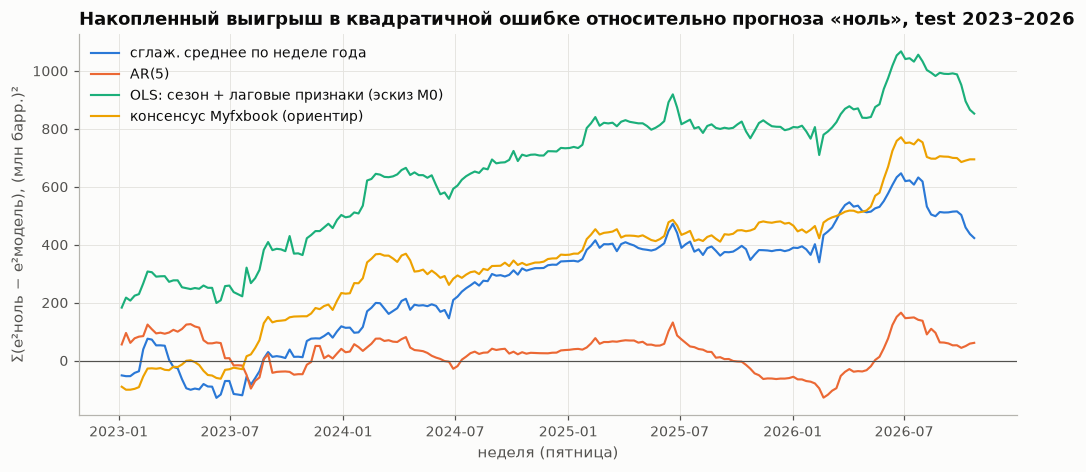

In [38]:
# «Прошлая неделя» не показана: она уходит до −4000 и сжимает шкалу (см. таблицу)
show = ["сглаж. среднее по неделе года", f"AR({p_ar})", "OLS: сезон + лаговые признаки (эскиз M0)",
        "консенсус Myfxbook (ориентир)"]
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, name in enumerate(show):
    e = y_test - preds.loc[te_idx, name]
    gain = (e_zero ** 2 - e ** 2).fillna(0).cumsum()
    ax.plot(te_idx, gain, color=u.SERIES[i], label=name)
ax.axhline(0, color=u.INK_MUTED, lw=0.8)
ax.set_title("Накопленный выигрыш в квадратичной ошибке относительно прогноза «ноль», test 2023–2026")
ax.set_ylabel("Σ(e²ноль − e²модель), (млн барр.)²")
ax.set_xlabel("неделя (пятница)")
ax.legend(loc="upper left")
plt.show()

**Вывод.**
- По AIC выбран AR(5) с коэффициентами 0,213 / 0,204 / 0,056 / 0,083 / −0,105.
- Test (199 недель, 2023-01-06…2026-10-23), MAE / RMSE / точность знака: «ноль» 4,23 / 5,43; «прошлая неделя» хуже всех —
  5,36 / 7,02 / 56 %; среднее по неделе года 4,02 / 5,28 / 63 %; **сглаженное среднее по неделе года — лучший наивный
  бейзлайн, 3,94 / 5,24 / 64 %**; AR(5) 4,07 / 5,41 / 55 % (выигрыш у нуля в пределах шума: ΔMAE −0,16 ± 0,25);
  сезонное + AR(5) 4,10 / 5,39 — переобучение (MAE на train 3,53). Тривиальная точность знака («всегда отбор») — 51,8 %.
- Эскиз M0 (OLS: сезон + 6 лаговых признаков) — 3,86 / 5,03 / 66 % (ΔMAE −0,37 ± 0,32). Консенсус Myfxbook — 3,70 / 5,02 / 67 %
  (ΔMAE −0,48 ± 0,23; n = 198, нет недели 2023-11-03). Консенсус лучше всех наивных бейзлайнов.
- Без 4 недель-выбросов test RMSE: OLS 4,58, консенсус 4,37, сглаженное сезонное 4,66, ноль 4,89. Паритет OLS с консенсусом
  по RMSE держится на выбросах — прежде всего на 2023-01-06: факт +19,0, OLS +5,7 (вероятно, через падение переработки НПЗ
  2022-12-30), консенсус −2,2. На остальных трёх выбросах все модели ошиблись примерно одинаково.
- corr(прогноз OLS − консенсус, surprise) на test = 0,197 (порог ±0,139): слабый, но значимый намёк, что лаговая информация EIA
  учтена в консенсусе не полностью. У сезонного среднего (0,056) и AR(5) (−0,025) такого эффекта нет. Это один сплит
  и одна проверка — нужна оценка со скользящим началом окна (rolling origin).

## Итоги

- **Цель M0 — ΔStocks коммерческой нефти, стационарный ряд** (σ 5,38 млн барр./нед, асимметрия +0,42, эксцесс 0,91,
  правый хвост тяжелее). Память короткая (ACF 0,25 на лагах 1–2), сезонность слабая (OOS R² по неделе года 5,5 %);
  у бензина и дистиллятов сезонность сильная (OOS R² 0,42 и 0,29).
- **73 % дисперсии национального ΔStocks — PADD 3**, регионы между собой почти не коррелируют (|corr| ≤ 0,18).
  Кушинг — 8 %, его запасы у минимума выборки (18,6 млн барр. 2026-07-24).
- **Приближённый баланс того же отчёта объясняет 51 % дисперсии ΔStocks** (57 % с ΔSPR), но он смещён (невязка в среднем +3,55)
  и публикуется вместе со ΔStocks, так что как признак это утечка. Adjustment выросла с ≈ 80–260 до ≈ 460–970 тыс. барр./сут
  (2021–2026) и стала шумнее; продажи из SPR (−221 млн барр. в 2022 г., −130 в апреле–сентябре 2026) сдвигают невязку.
- **Лаговый сигнал, доступный до релиза**, — в основном НПЗ: Δпереработки за 4 недели (corr −0,33), загрузка, ΔКушинг[t−1] (+0,25),
  ΔStocks[t−1] и баланс[t−1] (≈ +0,26, отчасти сезонность). Лаги импорта, экспорта, добычи и поставок пусты.
- **Бейзлайны на test 2023–2026** (MAE): ноль 4,23; прошлая неделя 5,36; сглаженное сезонное 3,94 (лучший наивный);
  AR(5) 4,07; эскиз OLS с лаговыми признаками 3,86; консенсус 3,70. Расхождение «OLS − консенсус» слабо коррелирует
  с surprise (0,197) — кандидат на проверку в M0.

**Проблемы качества данных**
- `crude_production`: округление до 100 тыс. барр./сут с 2018-06-01 по 2024-11-08 (337 недель, 148 без изменения):
  Δдобычи в этом окне — ступеньки.
- `crude_exports`: 61 неделя без изменения в 2015–2016 (34 и 27) — похоже на оценку, а не замер.
- Выбросы ΔStocks (|z| > 3): 2020-04-10, 2021-02-26, 2023-01-06, 2023-02-10, 2023-07-28, 2026-08-07 (4 из 6 — в test, включая
  первую неделю test). Погодные шоки потоков: 2017-09-01, 2021-02-19…03-05, 2021-09-03, 2022-12-30.
- Σ PADD 1–5 ≠ crude_stocks на 1–2 тыс. барр. в 286 неделях (округление, безвредно). Пропусков и разрывов в неделях нет.
- Единицы потоков в parquet не сохранены: тыс. барр./сут выведены из ID рядов EIA и масштаба. `approx_crude_balance_mmbbl` —
  не полный баланс (без ΔSPR и adjustment), название может ввести в заблуждение.
- Цель в этом ноутбуке — текущие (пересмотренные) данные EIA; surprise считается от первой публикации (по брифу они совпадают
  в пределах 0,05 в 589 из 607 недель). У консенсуса нет недели 2023-11-03.

**Выводы для моделирования**
- Признаки недели t брать только с недели t−1 и раньше: все потоки и баланс выходят в одном отчёте со ΔStocks.
- Хорошие кандидаты: сглаженное среднее по неделе года (считать только на train), Δпереработки НПЗ за 1–4 недели, загрузка НПЗ,
  ΔКушинг[t−1], ΔStocks[t−1]. Лаги импорта, экспорта и добычи можно не брать; Δдобычи в 2018–2024 — артефакт округления.
- Уровни с дрейфом (баланс, adjustment, запасы Кушинга и SPR) подавать разностями или нормировать скользящим окном;
  учитывать режимы SPR (2022, 2026).
- Для ошибки лучше устойчивая функция потерь (Huber/MAE): 4 крупных выброса в test заметно меняют RMSE-сравнения.
  Для оценки — rolling origin, а не только один сплит: волатильность внутри test меняется от 4,3 до 6,9.
- Консенсус уже лучше любого наивного бейзлайна по ΔStocks, поэтому M0 стоит оценивать по способности предсказать surprise,
  а не ΔStocks; лаговые признаки НПЗ и Кушинга — первое, что стоит проверить.